# Intended Learning Outcomes


In this tutorial you will learn about word embeddings and experiment with pretrained models. You will then built text classifiers on top of these word representations and explore a compositional (recurrent) encoder. Finally, you will perform some analysis of trained classifiers. 

## Suggested study plan

* Week 3: tutorial

| When | Werkcollege 1 | Werkcollege 2 |
| --- | --- | --- |
| Before |  [Setup](setup) your Jypyter Lab instance. Familiarise yourself with the section [Word Embeddings](word-embeddings) (incl. all of its subsections). Your goal is to get a sense of what the sections cover and the kind of knowledge they contain and/or depend on. If you find that some of them go into topics that you need to refresh, consider refreshing those before the live session too. | Familiarise yourself with the rest of the notebook. Your goal is to get a sense of what the sections cover and the kind of knowledge they contain and/or depend on. If you find that some of them go into topics that you need to refresh, consider refreshing those before the live session too.  |
| First half | Section: Word Embeddings | Section: Experiment (Data and Training) |
| Second half | Section: Text Classification Revisited | Section: Experiment (Analysis) |
| After |  Reflect on the various _Questions_ and _Exercises_ sections. | Reflect on the various _Questions_ and _Exercises_ sections. |

* Week 4: project
* Week 5: oral assessment

## Assessment

The practical (tutorial + mini project) is assessed orally, in the week _after_ the practical's conclusion. Make sure to seek the detailed schedule with your TA. 
The assessment is composed of some questions on the topics of the tutorial notebook and some questions on your mini project. The sections with _Questions_ or _Exercise_ in their header contain examples of the questions we may ask (both in form and level) about the tutorial part. Exercises marked as _suggested_ could be skipped in a first pass through the tutorial, but we may still ask questions about them. Instructions for the mini project can be found in the project notebook.

## Resources

* We often refer to [Chapter 5 of the textbook](https://web.stanford.edu/~jurafsky/slp3/5.pdf)
* Slides used in class: [check course website](https://nlp-illc.github.io/nlp1/).


## Setup 

We are using `python3.14` and the packages listed in `requirements.txt` at the root of the repository. The README.md file contains further instructions. 

In [1]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\ninaf\Downloads\nlp1-student-tutorial2-2026\nlp1-student-tutorial2-2026\.venv\Scripts\python.exe
3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]


In [2]:
%load_ext autoreload
%autoreload 2    

In [3]:
import nltk

nltk.download('opinion_lexicon')

[nltk_data] Downloading package opinion_lexicon to
[nltk_data]     C:\Users\ninaf\AppData\Roaming\nltk_data...
[nltk_data]   Package opinion_lexicon is already up-to-date!


True

In [4]:
import arviz as az

In [6]:
import sys
from pathlib import Path
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1  # we will reuse some things from last tutorial
import part2

In [7]:
# save models and outputs there to keep the directory tree organised
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 
results_folder

WindowsPath('results')

# Word Embeddings


By now, we know how to design a probabilistic model for text classification using the following strategy:
```mermaid
flowchart LR

A[$$~x$$] --> B(fixed encoder) -->|"$$\mathbf h(x)$$"| R(trainable softmax regression) --> P["$$p(1|x), \ldots, p(K|x)$$"]
style B fill:transparent
style A fill:transparent,stroke:0px,stroke-width:0px
```
with a _fixed_ (in the sense of not trainable) encoder that serves a _trainable_ softmax regression component with a fixed-dimensional, vector-valued representation of the text $x$. At this point, however, we have seen only rather crude encoders that  represent words as orthogonal dimensions in a large representation space and that represent texts by simple hand-crafted relations such as which words it contains and with what frequency do these occur. Anything much better than that, such as recognising syntactic voice or negation scope (amongst other things) requires solving a non-trivial NLP problem. 

In this design, we can readily recognise _at least_ two opportunities for improvement: a) better ways to represent _words_, and b) better ways to compose these word representations into a text representation that retains something about the _sequence_ of words in the text (and not only the unnordered _bag_ of words in it).  We will cover (a) in this section, and (b) in the next. 

The idea here is that we will use _pretrained word representations_ or **word embeddings**. You can think of a word embedding function as a table, with words indexing row vectors that represent those words in some way. See the _bag-of-characters_ example below, which _embeds_ words in the space of character counts (with dimensions that specific to the chars from `a` to `z`, and a dimension, the first one, for everything else).

In [7]:
from part2.utils import boc_emb
print(
    part2.utils.embeddings_to_str(
        {
            ".": boc_emb("."),        
            "!": boc_emb("!"),
            "a": boc_emb("a"),
            "another": boc_emb("another"),
            "day": boc_emb("day"),
            "good": boc_emb("good"),
            "just": boc_emb("just"),
            "regular": boc_emb("regular"),        
        },
        floatfmt=".0f"
    )
)

.        1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
!        1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
a        0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
another  0  1  0  0  0  1  0  0  1  0  0  0  0  0  1  1  0  0  1  0  1  0  0  0  0  0  0
day      0  1  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0
good     0  0  0  0  1  0  0  1  0  0  0  0  0  0  0  2  0  0  0  0  0  0  0  0  0  0  0
just     0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  1  1  1  0  0  0  0  0
regular  0  1  0  0  0  1  0  1  0  0  0  0  1  0  0  0  0  0  2  0  0  1  0  0  0  0  0


In [10]:
part2.utils.boc_emb??

Signature: part2.utils.boc_emb(word: str, vocab='abcdefghijklmnopqrstuvwxyz') -> 'np.array'
Source:   
def boc_emb(word: str, vocab=string.ascii_lowercase) -> 'np.array':
    """
    Produce a bag-of-characters embedding for a given word, in the space whose coordinates stand for
        0: count of characters not in string.ascii_lowercase
        i (other than 0): count of the ith character in string.ascii_lowercase
    """
    c2i = {c: i for i, c in enumerate(vocab, 1)}
    dim = len(c2i) + 1 # let's use 0 for everything not in vocab
    vector = np.zeros(dim)
    for c in word.lower():
        vector[c2i.get(c, 0)] += 1
    return vector
File:      ~\downloads\nlp1-student-tutorial2-2026\nlp1-student-tutorial2-2026\part2\utils.py
Type:      function

The embeddings above are made of whole counts, but that's not a general rule, and, even though they are displayed as a table, they need not be memorised as such, since they can be computed systematically by a rule (inspect the function `boc_emb`), but that's not a general rule either.

See that we can use the embedding function `boc_emb` to encode an entire text, so long as we have access to a tokenizer (to illustrate the point let's use string.split()) and a mechanism to _pool_ a sequence of word vectors into a single vector. Here's an example:

In [8]:
import numpy as np

print(f'sum_boc_enc("a good day") =', np.sum([boc_emb(w) for w in "a good day".split()], 0))

sum_boc_enc("a good day") = [0. 2. 0. 0. 2. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 2. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 1. 0.]


And here is another, with a different function doing the pooling:

In [9]:
print(f'mean_boc_enc("a good day") =', np.round(np.mean([boc_emb(w) for w in "a good day".split()], 0), 2))

mean_boc_enc("a good day") = [0.   0.67 0.   0.   0.67 0.   0.   0.33 0.   0.   0.   0.   0.   0.
 0.   0.67 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.33 0.  ]


Here's the plan for our current design of a fixed encoder: we will use a mechanism to _embed_ each token in isolation, obtaining as many vectors as there are tokens in $x$, and another mechanism to _pool_ these vectors together into a single _encoding_  of the text:
```mermaid
flowchart LR

A[$$~x$$] --> E(embed tokens) -->|"$$\mathbf e_1, \ldots, \mathbf e_{|x|}$$"| C(pool) -->|"$$\mathbf h$$"| R(softmax regression) --> P["$$p(1|x), \ldots, p(K|x)$$"]
style A fill:transparent,stroke:0px,stroke-width:0px
style E fill:transparent
style C fill:transparent
```
As before, the encoder is _outside_ the trainable probabilistic model, by the time a view of $x$ gets to the trainable softmax regressor, that view already corresponds to a single vector-valued representation of it.

Now, let's discuss some _meaningful_ ways to embed tokens.

## Vector Semantics and Trainable Embedding Models

Using vectors to capture the _meaning_ of words (and other linguistic objects) is generally referred to as _vector semantics_. There are _many_ models of vector semantics and most of them operationalise one or another variant of the _distributional hypothesis_, namely that _words that occur in similar contexts tend to have similar meanings_. We highly encourage you to read [section 5.0 to 5.4 of the textbook](https://web.stanford.edu/~jurafsky/slp3/5.pdf).

Here we will only sketch one of the possibilities:
* Imagine a model whose trainable parameters are word vectors, that is, for each symbol in the vocabulary of your favourite tokenizer, this model has a vector of $D$ real values that it takes to _represent_ that symbol; these vectors may be initialised at random. In the example below we have a tiny vocabulary (with `. ! a another bad day good just regular` and a catch-all-else symbol `<unk>`), we use a 10-dimensional space, and initialise our vectors randomly (from a standard normal distribution).

In [11]:
rng = np.random.RandomState(42)
demo_dim = 10
demo_emb_table = {
    "<unk>": rng.normal(size=demo_dim),
    ".": rng.normal(size=demo_dim),
    "!": rng.normal(size=demo_dim),
    "a": rng.normal(size=demo_dim),
    "another": rng.normal(size=demo_dim),
    "bad": rng.normal(size=demo_dim),
    "day": rng.normal(size=demo_dim),
    "good": rng.normal(size=demo_dim),
    "just": rng.normal(size=demo_dim),
    "regular": rng.normal(size=demo_dim),        
}
print(part2.utils.embeddings_to_str(demo_emb_table, floatfmt=".2f"))

<unk>     0.50  -0.14   0.65   1.52  -0.23  -0.23   1.58   0.77  -0.47   0.54
.        -0.46  -0.47   0.24  -1.91  -1.72  -0.56  -1.01   0.31  -0.91  -1.41
!         1.47  -0.23   0.07  -1.42  -0.54   0.11  -1.15   0.38  -0.60  -0.29
a        -0.60   1.85  -0.01  -1.06   0.82  -1.22   0.21  -1.96  -1.33   0.20
another   0.74   0.17  -0.12  -0.30  -1.48  -0.72  -0.46   1.06   0.34  -1.76
bad       0.32  -0.39  -0.68   0.61   1.03   0.93  -0.84  -0.31   0.33   0.98
day      -0.48  -0.19  -1.11  -1.20   0.81   1.36  -0.07   1.00   0.36  -0.65
good      0.36   1.54  -0.04   1.56  -2.62   0.82   0.09  -0.30   0.09  -1.99
just     -0.22   0.36   1.48  -0.52  -0.81  -0.50   0.92   0.33  -0.53   0.51
regular   0.10   0.97  -0.70  -0.33  -0.39  -1.46   0.30   0.26   0.01  -0.23


* Now, imagine that you have a large collection of pairs of words (for now, let's not worry about where these pairs come from); any one of these pairs is made of some 'target' word $t$ and some 'context' word $c$;
* moreover, a pair is _labelled_ as 1 if the target and the context word were seen to co-occur in some large corpus, and 0 otherwise; let's say that the definition of co-occurrence is basically _they co-occured in some sentence, at least once_;
Below you can see how the pairs in the list `demo_pairs` can be labelled according to this definition, in relation to a `demo_corpus`.

In [49]:
import itertools
demo_corpus = [
    "a good day",
    "a good day !",
    "bad day !",
    "another day",
    "just another day",
    "a regular day",
]
demo_pairs_in_corpus = set()
for text in demo_corpus:    
    demo_pairs_in_corpus.update(itertools.combinations(text.split(), 2))    

demo_pairs = [('good', 'day'), ('day', 'good'), ('good', 'bad'), ('bad', 'day'), ('day', 'another'), ('another', 'regular')]
print(f"{'demo pair':30}\tlabel")
for t, c in demo_pairs:
    print(f"{repr((t, c)):30}\t{1 if (t, c) in demo_pairs_in_corpus or (c, t) in demo_pairs_in_corpus else 0}")

demo pair                     	label
('good', 'day')               	1
('day', 'good')               	1
('good', 'bad')               	0
('bad', 'day')                	1
('day', 'another')            	1
('another', 'regular')        	0


The demo pairs can be constructed from the demo corpus with the help of some heuristics. For example, we could iterate over the pairs in the demo corpus and then for each $t$ sample some $c'$ it has not co-occured with (or sample $c'$ from a sentence other than the one that produced the pair, etc.). There are various strategies, this is just to give you an intuition of how these labelled pairs are _constructed_ by a procedure, and hence the more text we can observe, the more pairs we can construct. 

* We can use this kind of resource to train a _binary classifier_ intended to classify a pair of words as 1 (for words that do co-occur) vs. 0 (for words that do not co-occur) on the basis of the _similarity_ of the vectors that represent those words. This way we can fit our randomly initialised embeddings (in `demo_emb_table`) to the observed data, which will in principle improve the ability of our embeddings to discriminate co-occurring to non-co-occuring pairs. In other words, this will improve their ability to capture a notion of similarity, one useful to predict patterns of co-occurrence in text.
* We sketch and demo the model below: for didactic purposes, rather than using torch.nn.Module, we will implement the steps of SGD more transparently for you (we are still going to rely on torch for automatic differentiation of our loss node; for loss, we will use an estimate of the negative of the model's log-likelihood).

In [50]:
import scipy as sp
import scipy.special
from scipy.special import expit  # this is the same as the sigmoid function
import torch
import torch.nn as nn
import torch.autograd

class DemoLogisticCooccurrenceClassifier:

    def __init__(self, table: dict, unk="<unk>"):        
        """
        table: a dict mapping words (each a string) to their embeddings (each an np array)
        unk: the special word (str) to catch all unknown words
        device: a torch device (cpu is fine, this is just a demo)
        """
        # we construct trainable parameters for the embeddings, and initialise them with the 
        # arrays in the constructor
        self.table = {w: nn.Parameter(torch.tensor(v, dtype=torch.float32)) for w, v in table.items()}
        self.unk = unk

    def __call__(self, t: str, c: str):
        """
        Return the pmf over (co-occur=False, co-occur=True; 0 and 1, respectively) 
        given two words (t and c).

        For didactic purposes, here we deal with 1 word pair at a time.
        """
        u = self.table.get(t, self.table[self.unk])
        v = self.table.get(c, self.table[self.unk])
        # here we use the dot product as our notion of similarity 
        # note that dot product is related to cosine similarity (this may come in handy later on)
        s = torch.dot(u, v)
        # now we parameterise a pmf for binary outcomes using
        # the sigmoid of the dot product (scipy calls it expit)
        # this makes the dot product s the logit or score of a logistic regressor
        p = torch.sigmoid(s)        
        # we could return only p, then interpert this as the pfm of Bernoulli(p)
        # or return [1-p, p], then interpret this as the pmf of Categorical([1-p, p])
        # we will opt for the latter just so it looks more similar to last week's
        return torch.stack((1 - p, p), dim=-1)

    def loss(self, t, c, label):        
        """
        The loss for parameter estimation. We use an estimate of the negative of the model's log-likelihood.
        This is an _estimate_ because it is based on a single data point 
        (the exact log-likelihood function would use an entire training set).

        So, for an observed pair (t, c) with a given label, the loss is then
        - log p(label|t, c)

        We obtain the pmf, assess the prob it assigns to the observed label, and then compute the quantity above.        
        """
        u = self.table.get(t, self.table[self.unk])
        v = self.table.get(c, self.table[self.unk])
        pmf = self(t, c)
        return - torch.log(pmf[label])
    
    def loss_and_grads(self, t, c, label): 
        """
        The loss for parameter estimation and the gradients of the parameters involved in the computation of the loss. 
        For loss see the docstring of the method 'loss'.

        In this model, the estimated loss using (t, c, label) involves two parameter vectors, 
            * u = emb(t)
            * and v = emb(c)
        The other parameters are not involved in the computation, hence their grads are 0.

        Here we instantiate the loss and use autograd.grad to obtain gradients wrt u and v, 
         which we return in a dict (indexed by t and c).

        These grad vectors can be used to update the embeddings, see method 'update_embs'.
        """
        u = self.table.get(t, self.table[self.unk])
        v = self.table.get(c, self.table[self.unk])
        pmf = self(t, c)
        loss = - torch.log(pmf[label])
        params = tuple(v for v in self.table.values())
        grads = torch.autograd.grad(loss, (u,v))
        return loss, {t: grads[0], c: grads[1]}

    def update_embs(self, grads: dict, lr=0.1):        
        """
        Perform an in-place update of the embeddings whose grads are given. 
        As we are performing gradient descent on the loss, the simplest form of SGD update boils down to
            emb(w) = emb(w) - lr * grad(w)
            
        grads: dict mapping words (each a string) and the gradient vectors for their corresponding embeddings
            (these are obtained from loss_and_grads)
        lr: a learning rate (use less than 1.0)
        """
        # we are explicitly detaching the grad vector from the graph
        # this is to avoid a situation where you might change some options in autograd.grad 
        # and inadvertently compute grad of grad when playing with multiple calls to loss_and_grad
        with torch.no_grad():
            for w, g in grads.items():
                self.table[w].add_(g, alpha=-lr)

Let's see the pmf for a few pairs:

In [51]:
# here is a demo
demo_coocc_cls = DemoLogisticCooccurrenceClassifier(demo_emb_table)
demo_coocc_cls('good', 'day') # example
for t, c in demo_pairs:
    print(demo_coocc_cls(t, c).detach().cpu().numpy())

[0.908509   0.09149098]
[0.908509   0.09149098]
[0.9650593  0.03494072]
[0.21844578 0.7815542 ]
[0.4303304 0.5696696]
[0.06877345 0.93122655]


remember that we can view pmfs as bar plots:

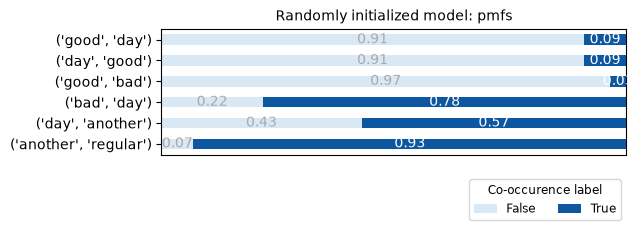

In [44]:
_ = part1.utils.plot_pmfs_barh(
    {repr((t, c)): demo_coocc_cls(t, c).detach().cpu().numpy() for t, c in demo_pairs}, 
    category_names=['False', 'True'],  # co-occurrence flag
    plottitle="Randomly initialized model: pmfs",
    legendtitle="Co-occurence label"
)

Let's do a little bit of training using a _positive_ data point:

In [54]:
# Check probabilities before training
print("Before training:")
print("Positive pair:", demo_coocc_cls('good', 'day').detach())
print("Negative pair:", demo_coocc_cls('bad', 'day').detach())

for i in range(10):
    # assess loss and gradient
    demo_loss, demo_grads = demo_coocc_cls.loss_and_grads('good', 'day', 1)
    print(f"Step: {i:2} Loss: {demo_loss.detach().cpu().numpy(): .4f}")
    # update embs
    demo_coocc_cls.update_embs(demo_grads)
print(f"Final Loss: {demo_coocc_cls.loss('good', 'day', 1).detach().cpu().numpy(): .4f}")   

# Check probabilities again
print("\nAfter training:")
print("Positive pair:", demo_coocc_cls('good', 'day').detach())
print("Negative pair:", demo_coocc_cls ('bad', 'day').detach())

Before training:
Positive pair: tensor([0.5444, 0.4556])
Negative pair: tensor([0.2742, 0.7258])
Step:  0 Loss:  0.7860
Step:  1 Loss:  0.2957
Step:  2 Loss:  0.1750
Step:  3 Loss:  0.1241
Step:  4 Loss:  0.0960
Step:  5 Loss:  0.0783
Step:  6 Loss:  0.0661
Step:  7 Loss:  0.0572
Step:  8 Loss:  0.0503
Step:  9 Loss:  0.0450
Final Loss:  0.0406

After training:
Positive pair: tensor([0.0398, 0.9602])
Negative pair: tensor([0.3743, 0.6257])


## Training on all pairs, example

In [45]:

for t, c in demo_pairs:
    for i in range(10):
        demo_loss, demo_grads = demo_coocc_cls.loss_and_grads(t, c, 1   if (t, c) in demo_pairs_in_corpus 
                                                                            or (c, t) in demo_pairs_in_corpus 
                                                                        else 0)
        #print(f"Step: {i:2} Loss: {demo_loss.detach().cpu().numpy(): .4f}")
        demo_coocc_cls.update_embs(demo_grads)
    print(f"Updated pmf for {repr((t, c))}: {demo_coocc_cls(t, c).detach().cpu().numpy()}")


Updated pmf for ('good', 'day'): [0.0439676 0.9560324]
Updated pmf for ('day', 'good'): [0.02141505 0.97858495]
Updated pmf for ('good', 'bad'): [0.977549   0.02245096]
Updated pmf for ('bad', 'day'): [0.07057297 0.929427  ]
Updated pmf for ('day', 'another'): [0.04851073 0.95148927]
Updated pmf for ('another', 'regular'): [0.8920025  0.10799746]


Let's see what happened:

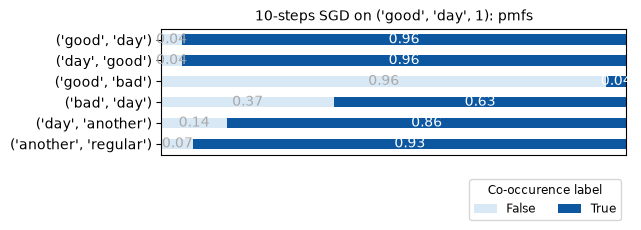

In [17]:
_ = part1.utils.plot_pmfs_barh(
    {repr((t, c)): demo_coocc_cls(t, c).detach().cpu().numpy() for t, c in demo_pairs}, 
    category_names=['False', 'True'],  # co-occurrence flag
    plottitle="10-steps SGD on ('good', 'day', 1): pmfs",
    legendtitle="Co-occurence label"
)

_After_ training (using a criterion such as MLE), we are left with a large collection of... you called it! Word embeddings.

See that the task is artificial (ie, detect co-occurrence under some made-up definition of co-occurrence), but as a _byproduct_ of learning to solve it, we get vectors that operationalise a version of the distributional hypothesis. Besides, artificial as it is, we can create a _lot_ of training data for it using whatever large corpus we can get.

The sketch above comes close to word2vec (see [section 5.5](https://web.stanford.edu/~jurafsky/slp3/5.pdf)), in its 'skip-gram' formulation (give or take a few hyper-parameters). 

### Questions

1. The pmf for `('good', 'day')` clearly changed, as did the pmf for `('day', 'good')`. Why is that?
2. Not only those two pmfs changed, but also other pmfs changed. Which and why did they change?

**Suggested exercise:** This is clearly not a complete training strategy (we have used a single positive word pair). Can you sketch a more complete strategy?

Your goal here is _not_ to develop a good and efficient embedding model (that would require too much engineering and it would cost you too much time), rather, just try to complete our own sketch of the training loop by incorporating: multiple positive examples as well as negative examples. This can help you if you are still struggle to understand how losses are computed (rather, estimated) and what torch optimisers do under the hood. Be mindful of your time investment. 

In [25]:
# Keep each observed pair occurrence, including repeats across sentences.
positive_examples = [
    (word1, word2, 1)
    for sentence in demo_corpus
    for word1, word2 in itertools.combinations(sentence.split(), 2)
]

# Sample negative pairs from vocabulary pairs that never co-occur.
vocab_words = [word for word in demo_emb_table if word != "<unk>"]
positive_pairs = {
    frozenset((word1, word2))
    for word1, word2, _ in positive_examples
}
negative_candidates = [
    (word1, word2, 0)
    for word1, word2 in itertools.combinations(vocab_words, 2)
    if frozenset((word1, word2)) not in positive_pairs
]

training_rng = np.random.default_rng(42)
sampled_indices = training_rng.choice(
    len(negative_candidates),
    size=len(positive_examples),
    replace=False,
)
training_examples = positive_examples + [
    negative_candidates[index] for index in sampled_indices
]

# Train a fresh model so the earlier demo model remains unchanged.
training_model = DemoLogisticCooccurrenceClassifier(demo_emb_table)

for epoch in range(10):
    epoch_loss = 0.0
    order = training_rng.permutation(len(training_examples))

    for index in order:
        word1, word2, label = training_examples[index]
        loss, grads = training_model.loss_and_grads(word1, word2, label)
        epoch_loss += loss.item()
        training_model.update_embs(grads, lr=0.1)

    print(f"Epoch {epoch + 1}: mean loss = {epoch_loss / len(training_examples):.4f}")



Epoch 1: mean loss = 1.3838
Epoch 2: mean loss = 0.6735
Epoch 3: mean loss = 0.4011
Epoch 4: mean loss = 0.2594
Epoch 5: mean loss = 0.1872
Epoch 6: mean loss = 0.1456
Epoch 7: mean loss = 0.1188
Epoch 8: mean loss = 0.1004
Epoch 9: mean loss = 0.0868
Epoch 10: mean loss = 0.0762


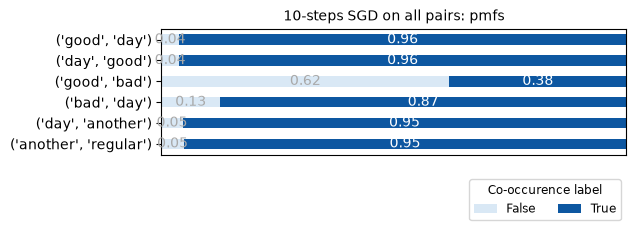

In [26]:
_ = part1.utils.plot_pmfs_barh(
    {repr((t, c)): training_model(t, c).detach().cpu().numpy() for t, c in demo_pairs},
    category_names=['False', 'True'],  # co-occurrence flag
    plottitle="10-steps SGD on all pairs: pmfs",
    legendtitle="Co-occurence label"
)

Word embeddings had a huge implact in NLP, and in many ways they, or the kind or research programme they launched, still do. Hence, we are now going to get familiar with the potential of pretrained embedding to capture useful generalisations and then apply them in text classification. 

## Pre-trained word embeddings

We are going to work with **pre-trained word embeddings**, the main reason being that training a useful embedding matrix is a non-trivial engineering challenge (mostly due to the volume of data needed).

A good package for downloading and using various pretrained word embedding models is python's `gensim`. It will give you structured and efficient access to these large matrices. 

For this part of the tutorial though, a library like gensim will hide many of the details that we want to bring to the foreground. So let's use a relatively small version of [Stanford's GloVe project](https://nlp.stanford.edu/projects/glove/)
> Jeffrey Pennington, Richard Socher, and Christopher Manning. ["Glove: Global vectors for word representation."](https://nlp.stanford.edu/pubs/glove.pdf) EMNLP 2014.


In [46]:
from pathlib import Path
from urllib.request import urlopen
import shutil

def download_pretrained(option):
    """
    You can use this to download GloVe (or similar) model using wget. 
    It's fine to download it through other means, but don't unzip the file (the rest of the notebook can 
    handle the file in its zipped format).

    This function returns the path which you can use for the loader class that follows.

    The function will skip the download if it detects the file in disk. If the file in disk is corrupted, you will have to delete the file first.
    """
    if option == 'glove':
        destination = "glove.2024.wikigiga.50d.zip"
        dims = 50
        skip_first = False
    elif option == 'fasttext':
        destination = "wiki-news-300d-1M.vec.zip"
        dims = 300
        skip_first = True
    else:
        raise ValueError(f"Unkonwn option: {option}")
        
    if not Path(destination).is_file():
        if option == 'glove':
            !wget https://nlp.stanford.edu/data/wordvecs/glove.2024.wikigiga.50d.zip
        elif option == 'fasttext':
            !wget https://dl.fbaipublicfiles.com/fasttext/vectors-english/wiki-news-300d-1M.vec.zip
        

    return destination, dims, skip_first

In [16]:
#Same class defined as above but with urlopen instead of !wget
from pathlib import Path
from urllib.request import urlopen
import shutil

def download_pretrained(option):
    """
    Downloads GloVe or FastText pretrained embeddings.
    Skips downloading if the file already exists.
    Keeps the downloaded file zipped.
    """

    if option == 'glove':
        destination = r"C:\Users\ninaf\Downloads\nlp1-student-tutorial2-2026\nlp1-student-tutorial2-2026\glove.2024.wikigiga.50d.zip"
        url = 'https://surfdrive.surf.nl/s/qYfZ6PiNrMLCwpS/download'
        dims = 50
        skip_first = False

    elif option == 'fasttext':
        destination = "wiki-news-300d-1M.vec.zip"
        url = "https://dl.fbaipublicfiles.com/fasttext/vectors-english/wiki-news-300d-1M.vec.zip"
        dims = 300
        skip_first = True

    else:
        raise ValueError(f"Unknown option: {option}")

    if not Path(destination).is_file():
        print(f"Downloading {option} embeddings...")

        try:
            with urlopen(url, timeout=300) as response:
                with open(destination, 'wb') as output:
                    shutil.copyfileobj(response, output)

            print("Download complete!")

        except Exception as e:
            # Remove incomplete download if something goes wrong
            Path(destination).unlink(missing_ok=True)
            raise RuntimeError(f"Download failed: {e}")

    else:
        print(f"File already exists: {destination}")

    return destination, dims, skip_first


Here we download the model:

In [17]:
%%time
# depends on internet connection (but say 5 minutes or less)
embtable_version, embtable_dims, embtable_metadata = download_pretrained('glove') # in case stanford.edu is down, use fasttext (but glove is preferred)
embtable_version, embtable_dims, embtable_metadata

File already exists: C:\Users\ninaf\Downloads\nlp1-student-tutorial2-2026\nlp1-student-tutorial2-2026\glove.2024.wikigiga.50d.zip
CPU times: total: 0 ns
Wall time: 483 μs


('C:\\Users\\ninaf\\Downloads\\nlp1-student-tutorial2-2026\\nlp1-student-tutorial2-2026\\glove.2024.wikigiga.50d.zip',
 50,
 False)

In `part2/clslib.py`, you will find `PretrainedEmbeddings`, which can be used to load embeddings to memory. We've documented it well for you, in case you want to familiarise yourself with the relevant steps.

In [149]:
import zipfile
from pathlib import Path

zip_path = Path("C:\\Users\\ninaf\\Downloads\\nlp1-student-tutorial2-2026\\nlp1-student-tutorial2-2026\\glove.2024.wikigiga.50d.zip")  # Change this to your ZIP filename
extract_path = Path("glove")

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction complete!")

Extraction complete!


In [153]:
from pathlib import Path

zip_path = Path(r"C:\Users\ninaf\Downloads\nlp1-student-tutorial2-2026\nlp1-student-tutorial2-2026\glove.2024.wikigiga.50d.zip")

print(zip_path.exists())

True


In [150]:
for file in Path("glove").rglob("*"):
    if file.is_file():
        print(file)

glove\wiki_giga_2024_50_MFT20_vectors_seed_123_alpha_0.75_eta_0.075_combined.txt


In [18]:
import inspect

print(inspect.getsource(download_pretrained))

def download_pretrained(option):
    """
    Downloads GloVe or FastText pretrained embeddings.
    Skips downloading if the file already exists.
    Keeps the downloaded file zipped.
    """

    if option == 'glove':
        destination = r"C:\Users\ninaf\Downloads\nlp1-student-tutorial2-2026\nlp1-student-tutorial2-2026\glove.2024.wikigiga.50d.zip"
        url = 'https://surfdrive.surf.nl/s/qYfZ6PiNrMLCwpS/download'
        dims = 50
        skip_first = False

    elif option == 'fasttext':
        destination = "wiki-news-300d-1M.vec.zip"
        url = "https://dl.fbaipublicfiles.com/fasttext/vectors-english/wiki-news-300d-1M.vec.zip"
        dims = 300
        skip_first = True

    else:
        raise ValueError(f"Unknown option: {option}")

    if not Path(destination).is_file():
        print(f"Downloading {option} embeddings...")

        try:
            with urlopen(url, timeout=300) as response:
                with open(destination, 'wb') as output:
                    shu

In [16]:
from pathlib import Path

print(list(Path(".").glob("*.zip")))

[WindowsPath('wiki-news-300d-1M.vec.zip')]


In [18]:
%%time
# about 30 seconds for GloVe
trained_emb_model = part2.clslib.PretrainedEmbeddings(embtable_version, embtable_dims, skip_first_line=embtable_metadata)

CPU times: total: 0 ns
Wall time: 10.7 μs


NameError: name 'embtable_version' is not defined

In [7]:
from pathlib import Path
import pickle

results_dir = Path(part2.__file__).resolve().parent / "results"
results_dir.mkdir(parents=True, exist_ok=True)
embedding_cache = results_dir / "pretrained_embeddings.pkl"

with embedding_cache.open("wb") as f:
    pickle.dump(trained_emb_model, f, protocol=pickle.HIGHEST_PROTOCOL)

NameError: name 'trained_emb_model' is not defined

In [11]:
import pickle

embedding_cache = part2_dir / "results" / "pretrained_embeddings.pkl"

with embedding_cache.open("rb") as f:
    trained_emb_model = pickle.load(f)

print(trained_emb_model.embed_word("king"))

[-0.39003   0.868335  0.684807 -0.758227  1.54142  -2.006612 -0.107967
  1.26053   0.259971 -0.587266  1.167608  0.216386  0.712985 -0.514837
 -0.531705 -0.250713  0.272562  0.420457  0.422036  0.27177   0.284001
  0.207707 -1.011175  0.179848  0.022646  0.190826  0.031093 -0.066455
 -1.041256 -0.207106 -0.603441 -0.189004  0.666082  0.122189 -0.373318
  0.543726 -0.258834  3.978247  0.525289  0.927056 -0.609059 -0.553423
 -0.297424  0.271807  0.41184  -0.055333 -0.55883  -0.065188  1.167179
  0.132492]


Internally, this object maintains two important things:
- a Vocabulary object that manages the correspondence between words and their 0-based unique ids
- an embedding matrix, whose rows align with the correspondence established by the vocabulary

In [23]:
print("Shape of embedding matrix:", trained_emb_model.vectors.shape)
print("Size of vocabulary:", len(trained_emb_model.vocab))
print(f"UNK token {trained_emb_model.vocab.default_index}:{trained_emb_model.vocab.default_word}") 
print(f"PAD token {trained_emb_model.vocab.index(trained_emb_model.pad_token)}:{trained_emb_model.pad_token}")
print("First few entries in the vocabulary:")
for _, (i, w) in zip(range(10), trained_emb_model.vocab.items()):
    print(f"{i}:{w}")

Shape of embedding matrix: (1287615, 50)
Size of vocabulary: 1287615
UNK token 1:<unk>
PAD token 0:<pad>
First few entries in the vocabulary:
0:<pad>
1:<unk>
2:the
3:,
4:.
5:of
6:to
7:and
8:in
9:a


And here we demo the key functions of PretrainedEmbeddings:

In [158]:
for word in ['person', 'human', 'city', 'place', 'camera-ready']:
    print(word, word in trained_emb_model, trained_emb_model.index(word), trained_emb_model.embed_word(word).shape)

person True 880 (50,)
human True 487 (50,)
city True 120 (50,)
place True 235 (50,)
camera-ready False 1 (50,)


You can see an embedding if you like (though like this it's hard to spot anything useful in it):

In [159]:
trained_emb_model.embed_word('person')
trained_emb_model.embed_word('person').shape

(50,)

Next we will play a bit of word embeddings in an attempt to see that they indeed do contain useful structure. You will also see that they are not free of problems.

## Exercise: Structure in Word Embeddings

Here we seek to convince ourselves that there's meaningful _structure_ in the embedding space. To that end, we start with something where the structure is clear to us: NLTK has an _opinion lexicon_, lists of words classified as typically expressing positive or negative sentiment. The exercise is to use this resource (we share a dataloader below) to analyse whether or not the pretrained embeddings contain information _about_ the typical polarity of words in English. 

Let's see if our embedding space happens to also contain some of this structrure. 

<details>
    <summary> Expand for a hint.
    </summary></br>

There are different ways to test this:
* A simple one is to use dimensionality reduction to plot the embeddings and then see if positive/negative words form somewhat separable clusters in the dimensionality-reduced space. If we don't see clusters, we cannot conclude much, after all, the original space might still contain enough information about sentiment, we would need a different analysis technique in that case.
* Another way is to use some form of unsupervised clustering (see for example, [k-means](https://scikit-learn.org/stable/modules/clustering.html#k-means)).

---

</details>
</details></br>


Below, you will find two lists of words (`pos_words` and `neg_words`), which are a) in the opinion lexicon and b) in the embedding model. Use these lists to 

In [160]:
pos_words, neg_words = part2.utils.sample_pos_and_neg_words(trained_emb_model)
print(f"{len(pos_words)} positive words; sample:", " ".join(pos_words[:10]))
print(f"{len(neg_words)} negative words; sample:", " ".join(neg_words[:10]))

1000 positive words; sample: cooperatively sweetly nicest endorsed entrust stronger dignified prudence gentle diligence
1000 negative words; sample: tamper dying ignominious sorrowful truant multi-polarization cracks sulk hypocritical smuttier


In [161]:
from sklearn.cluster import KMeans
import numpy as np

# Combine positive and negative words
words = pos_words + neg_words

# Retrieve the embedding vector for each word
X = np.array([
    trained_emb_model.embed_word(word)
    for word in words
])

# Apply K-Means
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X)



In [162]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

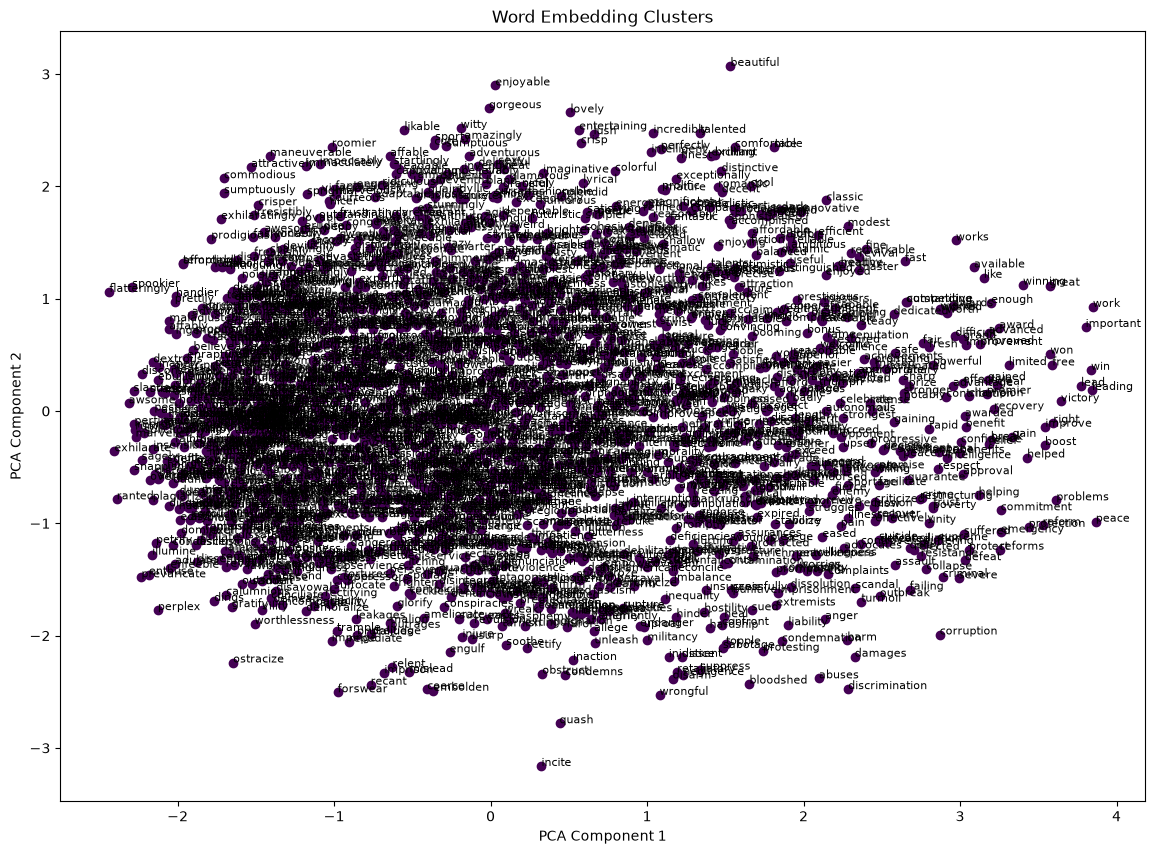

In [163]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 10))

for i, word in enumerate(words):
    plt.scatter(X_2d[i, 0], X_2d[i, 1], c=[clusters[i]], cmap="viridis")
    plt.annotate(word, (X_2d[i, 0], X_2d[i, 1]), fontsize=8)

plt.title("Word Embedding Clusters")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

Note, the seperation is much cleaner with Fasttext. In that case, it clearly forms two clusters. 

In [82]:
try:
    from part2 import solutions
except ImportError:
    print("You need your own implementation of cos_similarity")
else:
    solutions.analyse_embs(trained_emb_model, pos_words, neg_words)

You need your own implementation of cos_similarity


### Questions

1. Do you think an embedding space for English might contain information about, for example, parts of speech (i.e., syntactic word categories like _noun_, _verb_, _adjective_ and _adverb_)? Use your knowledge about how pretrained embeddings are typically trained to justify your answer.
2. Do you think your answer might change depending on the _language_ of the corpus used for training? Again, use your knowledge about how pretrained embeddings are typically trained to justify your answer.
3. Can you think of an alternative definition of co-ocurrence capable of having a decisive impact on the kind(s) of information pretained embeddings are likely to capture? Explain the rationale for your answer. For this question you can imagine access to additional levels of linguistic information to be available for the texts in your training corpus. 

## Exercises: Similarity and Analogies

Here you will use word embeddings to characterise the lexical similarity between words as well as use one such notion of similarity to play with word analogies.

1. Write a function to compute the _cosine similarity_ between two words (via their embeddings, ofc). Check the similarities you get for some examples. Here's a minimum list for you: use pairs from `person`, `human`, `place`, `city`, `car` (in our own implementation we observe person-person > person-human > person-place > person-city > person-car).
2. Then, using cosine as your notion of similarity, retrieve the top-k words that are most similar to a given word in the embedding space. Test this with some common words and see if the result is reasonable. Also, see if you can find some words for which the results aren't so reasonable. 
3. Inspect the result of _analogies_. For example, define the vector $\mathbf u = \operatorname{embed}(\textrm{professor}) - \operatorname{embed}(\textrm{man}) + \operatorname{embed}(\textrm{woman})$ and see which top-10 words are most similar in the space. You can also try flipping the man and the woman around: $\mathbf v = \operatorname{embed}(\textrm{professor}) - \operatorname{embed}(\textrm{woman}) + \operatorname{embed}(\textrm{man})$. Test other analogies, you can find examples by [Bolukbasi et al 2016](https://proceedings.neurips.cc/paper/2016/file/a486cd07e4ac3d270571622f4f316ec5-Paper.pdf). 

This sounds good and all, and word embeddings indeed had a huge impact on NLP, but there are problems that you should know about. The large corpora used to train embedding models contain toxic data, expressing harmful and biased views. Here is an excellent paper to seed your interests: [Bolukbasi et al 2016](https://proceedings.neurips.cc/paper/2016/file/a486cd07e4ac3d270571622f4f316ec5-Paper.pdf). With this word of warning, we go on to learn about how to _use_ word embeddings in our systems.

We suggest you complete these functions as a first step towards your solution, but you can also choose to organise your code differently.

In [20]:
import numpy as np

def cos_similarity(u, v):
    """
    Return the cosine similarity of two words in the embedding space.
    """
    u_embed = trained_emb_model.embed_word(u)
    v_embed = trained_emb_model.embed_word(v)

    return np.dot(u_embed, v_embed) / (
        np.linalg.norm(u_embed) * np.linalg.norm(v_embed)
    )


def _topk_ids_for_vector(query, E, k):
    """Return IDs of rows in E with highest cosine similarity to query."""
    if k <= 0:
        raise ValueError("k must be positive")

    E = np.asarray(E)
    query = np.asarray(query)
    denominators = np.linalg.norm(E, axis=1) * np.linalg.norm(query)
    similarities = np.full(E.shape[0], -np.inf)
    np.divide(E @ query, denominators, out=similarities, where=denominators > 0)
    return np.argsort(similarities)[-k:][::-1]


def topk_ids(word, E, k=10):
    """
    word: a string representing a word
    E: embedding matrix of shape [V, D]
    k: number of nearest neighbours

    Return the IDs of the k nearest words according to cosine similarity.
    """
    word_vector = trained_emb_model.embed_word(word)
    return _topk_ids_for_vector(word_vector, E, k)


def analogy(u, v, w, E, k=10):
    """
    u, v, w: words (strings)
    E: embedding matrix of shape [V, D]
    k: number of nearest neighbours

    Return IDs of the k nearest words to v - u + w.
    """
    u_embed = trained_emb_model.embed_word(u)
    v_embed = trained_emb_model.embed_word(v)
    w_embed = trained_emb_model.embed_word(w)

    target_vector = v_embed - u_embed + w_embed
    return _topk_ids_for_vector(target_vector, E, k)

In [12]:
from part2 import solutions
print("# Similarity")
solutions.demo_similarity(['person', 'human', 'place', 'city', 'car'], trained_emb_model)    
print("\n# Top-k")
solutions.demo_topk(['woman', 'man', 'king', 'queen', 'professor', 'nurse', 'positive'], 10, trained_emb_model)        
print("\n# Analogies")
for a, b, c in [('king', 'man', 'woman'), ('professor', 'man', 'woman'), ('nurse', 'man', 'woman')]:
    solutions.demo_analogy(a, b, c, 10, trained_emb_model)
    solutions.demo_analogy(a, c, b, 10, trained_emb_model)
    print()

ImportError: cannot import name 'solutions' from 'part2' (C:\Users\ninaf\OneDrive\Skrivebord\Cam\PhD\Logic Year UvA\Logic Year academic\NLP1\tutorials\part1\group-57\nlp1-student-gp57\nlp1-student-tutorial2-2026\nlp1-student-tutorial2-2026\part2\__init__.py)

In [29]:
def topk(query):
    ids = topk_ids(query, E, k=11)
    words = [
        trained_emb_model.word(int(i))
        for i in ids
        if trained_emb_model.word(int(i)) != query
    ][:10]
    print(f"Similar words to '{query}':")
    print(words)

In [31]:
topk('king')
topk('no')
topk('philosophy')

Similar words to 'king':
['prince', 'queen', 'brother', 'grandson', 'throne', 'son', 'uncle', 'ii', 'reign', 'emperor']
Similar words to 'no':
['not', 'any', 'nothing', 'if', 'because', 'what', '...', 'without', 'there', 'be']
Similar words to 'philosophy':
['theology', 'mathematics', 'philosophical', 'thesis', 'psychology', 'teaching', 'metaphysics', 'theological', 'taught', 'sociology']


In [ ]:
def topk_ids_w_labels(w, E, k):
    word_id = topk_ids(w, E, k=10)
    words = [trained_emb_model.word(int(i)) for i in word_id]
    widw = zip(words, word_id)
    return print(f"The {k} most similar words, ids to '{w}' are {[(w,int(i)) for w,i in widw]}")


In [48]:
for word in ['woman', 'man', 'king', 'queen', 'professor', 'nurse', 'positive']:
    topk_ids_w_labels(word, E, 10)

The 10 most similar words, ids to 'woman' are [('woman', 768), ('girl', 1768), ('mother', 782), ('boy', 1662), ('her', 70), ('she', 65), ('man', 311), ('herself', 2880), ('child', 962), ('old', 173)]
The 10 most similar words, ids to 'man' are [('man', 311), ('boy', 1662), ('old', 173), ('who', 39), ('woman', 768), ('another', 179), ('one', 50), ('young', 468), ('him', 104), ('turned', 852)]
The 10 most similar words, ids to 'king' are [('king', 705), ('prince', 1811), ('queen', 2114), ('brother', 1165), ('grandson', 7504), ('throne', 7056), ('son', 652), ('uncle', 5087), ('ii', 833), ('reign', 5526)]
The 10 most similar words, ids to 'queen' are [('queen', 2114), ('princess', 4361), ('lady', 2776), ('coronation', 14841), ('king', 705), ('elizabeth', 3118), ('royal', 1130), ('crown', 3133), ('prince', 1811), ('daughter', 1110)]
The 10 most similar words, ids to 'professor' are [('professor', 1227), ('university', 225), ('associate', 3757), ('harvard', 3348), ('sociology', 12423), ('eco

In [ ]:
for a, b, c in [('king', 'man', 'woman'), ('professor', 'man', 'woman'), ('nurse', 'man', 'woman')]:
    k = analogy(a, b, c, E, k=1).item()
    w = trained_emb_model.word(int(k))
    print(f"The solution to the analogy is: {a}:{b}::{w}:{c}")
    topk_ids_w_labels(w, E, k=10)

    #Not correct, fix later

The solution to the analogy is: king:man::woman:woman
The 10 most similar words, ids to 'woman' are [('woman', 768), ('girl', 1768), ('mother', 782), ('boy', 1662), ('her', 70), ('she', 65), ('man', 311), ('herself', 2880), ('child', 962), ('old', 173)]
The solution to the analogy is: professor:man::girl:woman
The 10 most similar words, ids to 'girl' are [('girl', 1768), ('boy', 1662), ('woman', 768), ('mother', 782), ('her', 70), ('girlfriend', 6558), ('baby', 2284), ('she', 65), ('girls', 1942), ('lover', 8616)]
The solution to the analogy is: nurse:man::man:woman
The 10 most similar words, ids to 'man' are [('man', 311), ('boy', 1662), ('old', 173), ('who', 39), ('woman', 768), ('another', 179), ('one', 50), ('young', 468), ('him', 104), ('turned', 852)]


In [33]:
cos_similarity('king', 'queen')
cos_similarity('king', 'dog')

np.float32(0.43872753)

In [39]:
for word in ['person', 'human', 'place', 'city', 'car','queen','humanoid','alien']:
    print(f"Cosine similarity between 'person' and '{word}': {cos_similarity('person',word)}")

Cosine similarity between 'person' and 'person': 1.0000001192092896
Cosine similarity between 'person' and 'human': 0.711064875125885
Cosine similarity between 'person' and 'place': 0.6786719560623169
Cosine similarity between 'person' and 'city': 0.5576913356781006
Cosine similarity between 'person' and 'car': 0.5977610945701599
Cosine similarity between 'person' and 'queen': 0.5110116004943848
Cosine similarity between 'person' and 'humanoid': 0.3124031722545624
Cosine similarity between 'person' and 'alien': 0.5900072455406189


### Questions

1. Reflect on your observations in exercises (1; cosine), (2; top-k) and (3; analogies). Can you explain what aspect of the model's training procedure might justify the observations you made?
2. Accepting that a certain embedding space contains information that's coherent with human assessment of lexical similarity, why should _cosine_ between two vectors in this space, as opposed to some other way to map two vectors to a single real number,  happen to be useful? 

# Text Classification Revisited

In this section we will revisit text classification with an MLP-parameterised softmax regressor. 
First, we will tackle the problem with a fixed encoder. Then, we will turn to a trainable and compositional encoder.

## Tokenizer

Because we intend to use a pretained embedding model, we will use a tokenization procedure that is coherent with how the embedding model's training data was processed. From what we gather for Stanford's GloVe and Google's word2vec models, a basic English tokenizer (like one of those in NLTK) on lowercased text will do a reasonable job at segmenting our texts into "words" that the embedding model gives coverage to. So that's what we will do in this tutorial. 

**Attention:** If you use a different embedding model in your project, you will need to adapt this strategy so it is reasonable in the context of that choice of model.

Moreover, for our convenience when developing models later on, we will give the tokenizer two responsibilities: 
1. As usual, the tokenizer segments a given string into a list of tokens
2. Additional, the tokenizer also maintains a vocabulary of known symbols and is able to convert tokens to unique 0-based identifiers.

In [167]:
class Tokenizer:
    def tokens(self, text: str) -> list:
        """Tokenize as a list of string tokens"""
        raise NotImplementedError("Implement me in subclass")
    def ids(self, text: str) -> list:
        """Tokenize as a list of token ids"""
        raise NotImplementedError("Implement me in subclass")

Our basic tokenizer uses `nltk` (you can check the docstring below, and the code in the repo):

In [3]:
part2.clslib.BasicTokenizer??

Init signature:
part2.clslib.BasicTokenizer(
    lowercase: bool,
    remove_punct: bool,
    remove_stopwords: bool,
    language='english',
    vocab: part2.clslib.Vocabulary = None,
)
Source:        
class BasicTokenizer(Tokenizer):
    """
    Tokenize text (str) using the call method of the object.
    
    Here are the  steps:
    1. lowercase (optional)
    2. remove punctuation (optional)
    3. NLT-tokenize 
    4. remove stopwords (optional)

    Different languages are only supported to the extent that NLTK supports them. 
    If you need something more complex, you need to write your own tokenizer.
    """

    def __init__(self, lowercase: bool, remove_punct: bool, remove_stopwords: bool, language='english', vocab: Vocabulary=None):
        """        
        lowercase: lowercase the text before tokenization
        remove_punct: remove punctuation 
        remove_stopwords: use NLKT to remove stopwords
        language: tells NLTK what language-specific rules to use
    

This is how we use the helper class.

BoW-style encoders cannot make very good use of punctuation and stopwords, so we discard them.

In [24]:
from tabulate import tabulate
import nltk
nltk.download('stopwords')

demo_texts = ['Dog bites man.', 'This tutorial is offered as part of NLP1, an MSc level course in the AI programme of the UvA.']

tokenizer_for_bow = part2.clslib.BasicTokenizer(
    lowercase=True, 
    remove_punct=True, 
    remove_stopwords=True, 
    language='english',
    vocab=trained_emb_model.vocab
)

for text in demo_texts:
    print(text)
    print(tabulate(list(zip(tokenizer_for_bow.ids(text), tokenizer_for_bow.tokens(text))), headers=['id', 'token']))    
    print()

Dog bites man.
   id  token
-----  -------
 3039  dog
16342  bites
  311  man

This tutorial is offered as part of NLP1, an MSc level course in the AI programme of the UvA.
   id  token
-----  ---------
42158  tutorial
 1123  offered
  157  part
    1  nlp1
24596  msc
  502  level
  760  course
 7388  ai
 3024  programme
45065  uva



[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ninaf\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


A compositional encoder on the other hand can make use of everything that's in the sequence, so we keep punctuation and stopwords:

In [27]:
tokenizer_for_rnn = part2.clslib.BasicTokenizer(
    lowercase=True, 
    remove_punct=False,
    remove_stopwords=False, 
    language='english',
    vocab=trained_emb_model.vocab
)

for text in demo_texts:
    print(text)
    print(tabulate(list(zip(tokenizer_for_rnn.ids(text), tokenizer_for_rnn.tokens(text))), headers=['id', 'token']))    
    print()

Dog bites man.
   id  token
-----  -------
 3039  dog
16342  bites
  311  man
    4  .

This tutorial is offered as part of NLP1, an MSc level course in the AI programme of the UvA.
   id  token
-----  ---------
   41  this
42158  tutorial
   17  is
 1123  offered
   21  as
  157  part
    5  of
    1  nlp1
    3  ,
   31  an
24596  msc
  502  level
  760  course
    8  in
    2  the
 7388  ai
 3024  programme
    5  of
    2  the
45065  uva
    4  .



## Encoders

Now let's use our tokenizer and our pretrained embedding vectors to design text encoders.

### Embed and Pool

We start by working with a fixed encoder that simply pools the pretrained embeddings of the words in the text together.

Now we are ready to code an encoder. Recall, our strategy for now is _embed then pool_. (An unshaded box denotes a _fixed_, in the sense of non-trainable, component)

```mermaid
flowchart LR

A[$$~x$$] --> B1("tokenizer (and vocab)") -->|"$$\operatorname{id}(w_1), \ldots, \operatorname{id}(w_l)$$"| B2(embedding model) -->|"$$\mathbf{e}_1, \ldots, \mathbf{e}_l$$"| B3(pooling)--> B("$$\mathbf h(x)$$")
style B fill:transparent,stroke:0px,stroke-width:0px
style A fill:transparent,stroke:0px,stroke-width:0px
style B1 fill:transparent
style B2 fill:transparent
style B3 fill:transparent
```

We will be using `torch`, so we will design our key components already as instances of `nn.Module`. This will make it easier when, later on, we designs certain parts of it to be trainable.

Torch modules should be designed to work with _batched_ inputs, as this exploits parallelism on GPU. 'Batching' inputs means to stack multiple inputs together in one tensor and perform the same sort of computation for each and every input in parallel. When inputs can be represented as objects of fixed and identifical dimensionality, batching is mostly straightforward. This is the case for embed-and-pool, after all, each and every text $x$ gets a fixed $D$-dimensional vector $\mathbf h(x)$, no matter the content of $x$ itself. That said, we will design the torch version of this encoder such that the embedding operation and the pooling operation happen _inside_ the neural architecture, as opposed to outside as a preprocessing step. This will make it easier to control what parts of the encoder are trainable, when the time comes. For that reason, we need to discuss batching already.

Suppose we are batching three sequences of token ids: `[1, 2, 3]`, `[6, 2]` and `[2, 1, 4, 5]`. As they differ in length, we use the following trick to batch them into a single tensor:

In [170]:
ex_batch = torch.tensor(
    [
        [1, 2, 3, 0],
        [6, 2, 0, 0],
        [2, 1, 4, 5]
    ]
) 
ex_batch

tensor([[1, 2, 3, 0],
        [6, 2, 0, 0],
        [2, 1, 4, 5]])

That is we extend the shorter sequences with 0s (or whatever the id of the 'pad' token is) until they match the longest sequence in length.
The special 'pad' token plays two roles: a) it makes the batched sequences fit in a 2D tensor of shape `(batch_size, max_seq_len)`, b) it allows us to distinguish 'valid' positions (actual tokens) from padding. 

Here we show a quick demonstration of what we mean by (b).

In [171]:
torch.sum(ex_batch.ne(0), dim=-1) == torch.tensor([3, 2, 4])

tensor([True, True, True])

Batching is such a common operation that torch offers helper code for it, see below.

In [172]:
from torch.nn.utils.rnn import pad_sequence   

def collate_sequences(sequences, padding_value=0):    
    """
    This is a helper to batch tokenized sequences of variable length into a torch tensor with shape (num_sequences, longest_seq_length)
    sequences: list of tokenized texts (each text is a list of token ids)
    padding_value: the id of the pad symbol
    """
    lengths = torch.tensor([len(x) for x in sequences], dtype=torch.long)
    x = pad_sequence([torch.tensor(seq, dtype=torch.long) for seq in sequences], batch_first=True, padding_value=padding_value)
    return x

Here is a demo:

In [173]:
collate_sequences([tokenizer_for_bow.ids(text) for text in demo_texts], tokenizer_for_bow.vocab.index(trained_emb_model.pad_token))

tensor([[ 3039, 16342,   311,     0,     0,     0,     0,     0,     0,     0],
        [42158,  1123,   157,     1, 24596,   502,   760,  7388,  3024, 45065]])

And now we are ready to _embed and pool_.

**Suggested exercise:** complete the class below and compare your implementation to ours.

In [174]:
import torch
import torch.nn as nn

class EmbedAndPoolEncoder(nn.Module):
    """
    This encoder embeds a sequence of token ids and then pools the result along sequence length using
    sum or mean.
    """
    def __init__(self, embedding_matrix, average_pool=True, padding_idx=0, freeze_embeddings=True):
        """
        embedding_matrix: a torch tensor of shape (vocab_size, emb_dim)
        average_pool: use True for mean and False for sum
        padding_idx: the id of the pad token (this is for batched computation)
            suppose we are batching three sequences [1, 2, 3], [6, 2] and [2, 1, 4, 5]
            as they differ in length, we use the following trick to batch them into a single tensor
            [
                [1, 2, 3, 0],
                [6, 2, 0, 0],
                [2, 1, 4, 5]
            ]
            that is we extend the shorter sequences with 0s until they match the longest sequence
        freeze_embeddings: tells torch that we are not updating the parameters in the embedding matrix
        """
        super().__init__()
        self.average_pool = average_pool
        # Pretrained embeddings
        self.embedding = nn.Embedding.from_pretrained(
            embedding_matrix, 
            freeze=freeze_embeddings,
            padding_idx=padding_idx
        )        
        

    @property
    def enc_dim(self):
        return self.embedding.embedding_dim

    def forward(self, x):     
        """
        Encodes each sequence in the batch as a single vector of size emb_dim.
        
        x: token ids with shape (batch_size, max_seq_length, emb_dim)        
        """
        # [..., max_seq_length, emb_dim]
        e = self.embedding(x)  
        raise NotImplementedError("How about you try to implement the rest of this method?")

If you implement it yourself, you can compare yours to ours.

In [175]:
def test_embed_and_pool(emb_vectors, pad_id, tokenizer):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(42)
        your_embed_and_pool_encoder = EmbedAndPoolEncoder(
            torch.tensor(emb_vectors, dtype=torch.float32), 
            freeze_embeddings=True, 
            padding_idx=pad_id
        )
        your_h = your_embed_and_pool_encoder(torch.tensor([tokenizer.ids('Dog bites man.')]))
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(42)
        our_embed_and_pool_encoder = part2.clslib.EmbedAndPoolEncoder(
            torch.tensor(emb_vectors, dtype=torch.float32), 
            freeze_embeddings=True, 
            padding_idx=pad_id
        )
        our_h = our_embed_and_pool_encoder(torch.tensor([tokenizer.ids('Dog bites man.')]))

    assert torch.allclose(your_h, our_h)

In [176]:
try: 
    test_embed_and_pool(
        trained_emb_model.vectors, 
        trained_emb_model.vocab.index(trained_emb_model.pad_token), 
        tokenizer_for_bow
    )
except NotImplementedError:
    print("Implement EmbedAndPoolEncoder or continue to our own demo.")

Implement EmbedAndPoolEncoder or continue to our own demo.


A little demo using our own implementation. 

In [177]:
pooled_emb_encoder = part2.clslib.EmbedAndPoolEncoder(
    torch.tensor(trained_emb_model.vectors, dtype=torch.float32), 
    freeze_embeddings=True, 
    padding_idx=trained_emb_model.vocab.index(trained_emb_model.pad_token)
)

In [178]:
pooled_emb_encoder(torch.tensor([tokenizer_for_bow.ids('Dog bites man.')]))

tensor([[-0.8792, -0.4464, -0.1673, -0.5795,  0.1341,  0.2897,  0.3379,  0.8522,
          0.0432, -1.0165, -0.2199, -0.0615,  0.4377,  0.2574, -0.3567,  0.4033,
         -0.1489, -0.7463,  0.1658,  0.1006, -0.7823,  0.4596,  0.2816, -0.4065,
         -0.2243, -0.2226, -0.2611,  0.2402,  0.3591,  0.2059, -1.1366, -0.6408,
          0.1046, -0.1460,  0.0695,  0.7688, -0.1146,  3.1749,  0.1172, -0.5245,
          0.2098,  0.6758, -0.2537,  0.1896, -0.5446,  0.0970,  0.1139,  0.2417,
          0.2653,  1.0131]])

Remember one of the limitations of BoW-type encoders? This encoder uses word representations that are dense and pretrained but the result still is a BoW-type encoder.

In [179]:
torch.allclose(
    pooled_emb_encoder(torch.tensor([tokenizer_for_bow.ids('Dog bites man.')])),
    pooled_emb_encoder(torch.tensor([tokenizer_for_bow.ids('Man bites dog.')])),
)

True

Let's see that our batching function pads things correctly:

In [180]:
torch.allclose(
    # stack the encodings, computed in sequence
    torch.stack([pooled_emb_encoder(torch.tensor(tokenizer_for_bow.ids(text))) for text in demo_texts]),
    # stack the sequence, then encode in parallel
    pooled_emb_encoder(collate_sequences([tokenizer_for_bow.ids(text) for text in demo_texts], tokenizer_for_bow.vocab.index(trained_emb_model.pad_token))),    
)

True

### RNN Encoder

A _recurrent_ encoder achieves a non-linear composition of a sequence of vectors. 
It does so with a computation that scales linearly in sequence length, but with a fixed parameterisation (that is, the parameterisation does not change as a function of sequence length). 

```mermaid
flowchart LR

A[$$~x$$] --> B1("tokenizer (and vocab)") -->|"$$\operatorname{id}(w_1), \ldots, \operatorname{id}(w_l)$$"| B2(embedding model) -->|"$$\mathbf{e}_1, \ldots, \mathbf{e}_l$$"| B3(RNN encoder)--> B("$$\mathbf h_1(x), \ldots, \mathbf h_l(x)$$")
style B fill:transparent,stroke:0px,stroke-width:0px
style A fill:transparent,stroke:0px,stroke-width:0px
style B1 fill:transparent
style B2 stroke-dasharray:5 5
```

The key to a recurrent encoder is that its computation has a state (a vector of some predefined size) which is iteratively updated as the recurrent encoder processes the input sequence. The $i$th input $\mathbf e_i$ combines with the previous state $\mathbf h_{i-1}$ producing the new state $\mathbf h_i$:

```mermaid
flowchart LR
    
hprev["$$\mathbf h_{i-1}$$"] --> state["RNN cell"]
wi["$$\mathbf e_i$$"] --> state
state --> hi["$$\mathbf h_i$$"]

```


The simplest RNN encoder is based on what is known as an Elman network. We sketch it below.
* Suppose the input is a sequence of vectors $\mathbf e_1, \ldots, \mathbf e_l$, each $D$-dimensional;
* The RNN encoder has an initial state, say $\mathbf h_0 = \mathbf 0$, an $H$-dimensional vector of zeros;
* The state is updated iteratively as follows, for $i \in \{1, \ldots, l\}$: $\mathbf h_i = \tanh(\mathbf W \mathbf e_i + \mathbf U \mathbf h_{i-1} + \mathbf b)$ where $\mathbf b \in \mathbb R^H, \mathbf U \in \mathbb R^{H\times H}, \mathbf W \in \mathbb R^{H\times D}$  are the encoder's trainable parameters;
* Then $\mathbf h_l$ is a non-linear representation of the entire sequence.

A torch implementation and a demostration can be seen below.
Some remarks about implementation: we choose to treat the embedding parameters as internal to the RNN encoder class (but the RNN cell itself is a concept independent of the embedding model), the embedding vectors maybe treated as trainable parameters or not (that's why we dashed it in the diagram above), and, finally, most APIs return the entire sequence of hidden states $\mathbf h_1, \ldots, \mathbf h_l$, but in this tutorial we will return 1 state (the final one).

**Suggested exercise:** complete the code below and compare your implementation to ours.

In [181]:
class RNNEncoder(nn.Module):
    def __init__(self, hidden_size, embedding_matrix, padding_idx=0, freeze_embeddings=True):
        """        
        hidden_size: the size of the recurrent state

        To simplify implementation, we treat the embedding layer as part of the encoder. 
        
        embedding_matrix: word vectors            
        padding_idx: the id of the pad token
        freeze_embeddings: treat the vectors as frozen or not
        """
        super().__init__()
        vocab_size, embedding_dim = embedding_matrix.shape
        self.emb_dim = embedding_dim
        self.pad_idx = padding_idx
        self.hidden_size = hidden_size
        # Pretrained embeddings
        self.embedding = nn.Embedding.from_pretrained(
            embedding_matrix, 
            freeze=freeze_embeddings,
            padding_idx=padding_idx
        )
        # Here's the design of the update
        # see that we can achieve the same parameterisation as explained above
        # via h[i] = tanh(linear(concat(e, h[i-1])))
        # so the key trainable component of the simplest recurrent encoder is this one non-linear transformation with D+H inputs and H outputs
        self.elman_net = nn.Sequential(
            nn.Linear(embedding_dim + hidden_size, hidden_size),
            nn.Tanh(),            
        )  

    @property
    def enc_dim(self):
        return self.hidden_size
        
    def forward(self, x):
        """
        Encode each sequence in the batch into a single H-dimensional vector.
        
        x: a batch of sequences of token ids
        """
        
        embeddings = self.embedding(x)  # (batch_size, max_len, emb_dim)
        # initial state
        # zeros on the same device and with the same dtype as embeddings.        
        h = torch.zeros(x.shape[:-1] + (self.hidden_size,), dtype=embeddings.dtype, device=embeddings.device)

        raise NotImplementedError("Do you want to try to code the rest of this method yourself?")

If you implement it yourself, you can compare yours to ours.

In [182]:
def test_rnn_enc(emb_vectors, pad_id, tokenizer):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(42)
        your_rnn_enc = RNNEncoder(2, embedding_matrix=torch.tensor(emb_vectors, dtype=torch.float32), padding_idx=pad_id, freeze_embeddings=True)        
        your_h = your_rnn_enc(torch.tensor([tokenizer.ids('Dog bites man.')]))
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(42)
        our_rnn_enc = part2.clslib.RNNEncoder(2, embedding_matrix=torch.tensor(emb_vectors, dtype=torch.float32), padding_idx=pad_id, freeze_embeddings=True)        
        our_h = our_rnn_enc(torch.tensor([tokenizer.ids('Dog bites man.')]))

    assert torch.allclose(your_h, our_h)

In [183]:
try: 
    test_rnn_enc(
        trained_emb_model.vectors, 
        trained_emb_model.vocab.index(trained_emb_model.pad_token), 
        tokenizer_for_rnn
    )
except NotImplementedError:
    print("Implement RnnEncoder or continue to our own demo.")

Implement RnnEncoder or continue to our own demo.


The demo uses our own implementation (which you can compare to yours, if you wrote one):

In [184]:
toy_vocab = part2.clslib.Vocabulary(['<pad>', '<unk>', 'man', 'bites', 'dog'], default='<unk>', frozen=True)
list(toy_vocab.items())

[(0, '<pad>'), (1, '<unk>'), (2, 'man'), (3, 'bites'), (4, 'dog')]

In [185]:
toy_tokenizer = part2.clslib.BasicTokenizer(True, False, False, 'english', toy_vocab)
toy_tokenizer.ids('Dog bites man.')

[4, 3, 2, 1]

In [186]:
toy_texts = ['man', 'dog', 'man bites', 'dog bites', 'man bites dog', 'dog bites man']
toy_batch = collate_sequences([toy_tokenizer.ids(text) for text in toy_texts], toy_tokenizer.vocab.index('<pad>'))
toy_batch

tensor([[2, 0, 0],
        [4, 0, 0],
        [2, 3, 0],
        [4, 3, 0],
        [2, 3, 4],
        [4, 3, 2]])

In [187]:
# some 3-dimensional embeddings for the words in the toy vocab
toy_matrix = torch.tensor([[0, 0, 0], [0, 0, 0], [1, 0, 0], [0, 1, 0], [0, 0, 1]], dtype=torch.float32)
toy_pool_enc = part2.clslib.EmbedAndPoolEncoder(toy_matrix, padding_idx=0, freeze_embeddings=True)
toy_rnn_enc = part2.clslib.RNNEncoder(2, embedding_matrix=toy_matrix, padding_idx=0, freeze_embeddings=True)

Here we compare the two forms of encoding. See the BoW-style effect of _embed and pool_ and how the non-linear composition function of the RNN manages to retain the information the `dog bites man` and `man bites dog` are different sequences.

In [188]:
def np_and_round(t, decimals=4):
    return np.round(t.detach().cpu().numpy(), decimals=decimals)
print(tabulate(list(zip(toy_texts, np_and_round(toy_pool_enc(toy_batch)), np_and_round(toy_rnn_enc(toy_batch)))), headers=['text', 'avg emb', 'rnn']))

text           avg emb                 rnn
-------------  ----------------------  -----------------
man            [1. 0. 0.]              [-0.329   0.6236]
dog            [0. 0. 1.]              [-0.1236  0.6013]
man bites      [0.5 0.5 0. ]           [-0.1059  0.6249]
dog bites      [0.  0.5 0.5]           [-0.1307  0.5943]
man bites dog  [0.3333 0.3333 0.3333]  [0.0043 0.653 ]
dog bites man  [0.3333 0.3333 0.3333]  [-0.213   0.6744]


### LSTM Encoder

The architecture of the basic RNN encoder from above leads to problems when learning via gradient-based optimisation (eg., vanishing and exploding gradients), so, in practice, we never use it. Instead, we use a GRU or an LSTM.

We are not going to be writing our own LSTM class, rather we are going to use a stable and debugged implementation. 
Do check the design of the LSTMEncoder we wrote for you, it is rather straightforward, but you will learn a couple of things that are important for efficiency (for example, we rarely write the `for` loop that updates the state ourselves, rather, we delegate it to an efficient torch helper).

Some details about recurrent models:
* an LSTM step involves the maintenance of two hidden vectors (a cell and a state), so when you use `torch.nn.LSTM` you will notice that it returns pairs of vectors for each step;
* you can stack recurrent architectures, if you `torch.nn.LSTM` you will notice a `num_layers` argument in the constructor;
* you might know the regularisation technique called `dropout`, well for recurrent models the typical dropout you know (randomly zeroing out units before a linear transformation) cannot be applied to the internal hidden states because the recurrence will lead to the complete destruction of any signal as sequence length increases; there are two options that are more theoretically justified: dropout with a fixed mask across all steps (rather than independently resampled in each step) and something called _word dropout_ (dropout at the level of inputs to the recurrent model), the former is rarely supported by NN packages (like torch), the latter is demonstrated in our own implementation `part2.clslib.LSTMEncoder` (it's worth learning from it).


In [189]:
toy_lstm_enc = part2.clslib.LSTMEncoder(2, embedding_matrix=toy_matrix, padding_idx=0, freeze_embeddings=True)

In [190]:
toy_lstm_enc(toy_batch)

tensor([[-0.1634, -0.0687],
        [-0.2171, -0.1231],
        [-0.0690, -0.1535],
        [-0.0462, -0.1752],
        [-0.2213, -0.1550],
        [-0.1736, -0.1555]], grad_fn=<SelectBackward0>)

**Suggested exercise:** Using our LSTMEncoder as a guide, try implementing a _bidirectional_ recurrent encoder. See that `torch.nn.LSMT` has a `bidirectional` argument (have a look at the documentation to understand what `torch.nn.LSTM` returns via its forward method in this case):

In [ ]:
# torch.nn.LSTM?

## Softmax Regressor

The document representation we obtained (pooled vectors from word embeddings comprising the document) is passed to a neural network softmax regressor.
One little detail, in practice, for numerical stability, we use `LogSoftmax` as output activation, so technically the model predicts log-probability masses (rather than probability masses):

```mermaid
flowchart LR

B("$$\mathbf h(x)$$") --> R1(trainable feed-forward NN) --> R2(LogSoftmax) --> P["$$\log p(1|x), \ldots, \log p(K|x)$$"]
style B fill:transparent,stroke:0px,stroke-width:0px
```

Let's implement this in torch.

In [191]:
class SoftmaxRegressor(nn.Module):
    """
    This is a softmax regressor, 
     it works with encoded text h(x) as input.
    The map from h(x) to outputs uses an MLP.

    One important detail: for numerical stability the output is not softmax-activitate, 
     rather, it is logsoftmax-activated. This means the outputs are log prob masses, not prob masses.
    """
    def __init__(self, hidden_size1, hidden_size2, num_classes, encoder: nn.Module):
        """
        hidden_size1: size of first hidden layer (in the output transformation)
        hidden_size2: size of second hidden layer
        num_classes: number of possible classes
        encoder: an nn.Module that maps each x to a single vector of size encoder.enc_dim
        """
        super().__init__()
        self.encoder = encoder      
        self.num_classes = num_classes
        raise NotImplementedError("Do you want to try and implement it yourself?")

    def forward(self, x):  
        """
        for each sequence in the batch, encode it, then map the result to log probs for the possible classes
        return a tensor with shape (batch_size, num_classes) of log probs
        """
        raise NotImplementedError("Do you want to try and implement it yourself?")

As before, you can compare your implementation to ours.

In [192]:
def test_softmax_regressor(encoder, num_classes, tokenizer):
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(42)
        your_sr = SoftmaxRegressor(10, 10, num_classes, encoder)
        your_log_probs = your_sr(torch.tensor([tokenizer.ids('Dog bites man.')]))
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(42)
        our_sr = part2.clslib.SoftmaxRegressor(10, 10, num_classes, encoder)
        our_log_probs = our_sr(torch.tensor([tokenizer.ids('Dog bites man.')]))

    assert torch.allclose(your_log_probs, our_log_probs)

In [193]:
try:    
    test_softmax_regressor(part2.clslib.EmbedAndPoolEncoder(torch.tensor(trained_emb_model.vectors, dtype=torch.float32)), 4, tokenizer_for_bow)
except NotImplementedError:
    print("Implement SoftmaxRegressor or continue to our own demo.")

Implement SoftmaxRegressor or continue to our own demo.


The demo uses our own code.

In [194]:
bow_sr = part2.clslib.SoftmaxRegressor(50, 50, 4, part2.clslib.EmbedAndPoolEncoder(torch.tensor(trained_emb_model.vectors, dtype=torch.float32)))
# embed-and-pool makes the two texts identical, hence their conditional log probs cannot differ
torch.allclose(bow_sr.forward(torch.tensor([tokenizer_for_bow.ids('dog bites man')])), bow_sr.forward(torch.tensor([tokenizer_for_bow.ids('man bites dog')])))

True

In [195]:
# LSTMs can arrive at different encodings for these two texts, hence their conditional log probs differ
lstm_sr = part2.clslib.SoftmaxRegressor(50, 50, 4, part2.clslib.LSTMEncoder(50, torch.tensor(trained_emb_model.vectors, dtype=torch.float32)))
not torch.allclose(lstm_sr.forward(torch.tensor([tokenizer_for_rnn.ids('dog bites man')])), lstm_sr.forward(torch.tensor([tokenizer_for_rnn.ids('man bites dog')])))

True

We are now ready to experiment with these models.

# Experiment

## Data

This is re-using the code from the first tutorial to load and prepare our training and validation data.

In [9]:
from datasets import load_dataset

agnews_outcome_space = part1.clslib.NamedClasses(['world', 'sports', 'business', 'tech/sci-fi'])
print(agnews_outcome_space)

#Loading our training corpus
dataset = load_dataset("fancyzhx/ag_news") 
print(dataset)

0: world, 1: sports, 2: business, 3: tech/sci-fi


DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


An example from the training data:

In [197]:
print("Text:", dataset["train"]["text"][0])
print("Gold label (id):", dataset["train"]["label"][0])
print("Gold label (name):", agnews_outcome_space.name(dataset["train"]["label"][0]))

Text: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
Gold label (id): 2
Gold label (name): business


As in this tutorial we study a number of designs, we use cross-validation to obtain more reliable estimates of their merits in classification.

In [13]:
%%time
my_seeds = [0] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]  
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["text"], dataset["train"]["label"])),  
            k=num_folds,
            seed=seed
        )
    )

CPU times: total: 3.55 s
Wall time: 3.89 s


We will not be using the test set `dataset["test"]` for most of this tutorial, but we already split it in a `devtest` set (for some analysis at the end) and its complement (as an unseen dataset).

In [199]:
len(dataset["test"]["text"])

7600

In [34]:
my_test_sets = []
devtest_size = 100 * len(agnews_outcome_space)
for seed in my_seeds:
    my_test_sets.append(part1.experiment.split_test_devtest(zip(dataset["test"]["text"], dataset["test"]["label"]), devtest_size, seed=seed))

In [201]:
my_test_sets[0].keys(), len(my_test_sets[0]['devtest']), len(my_test_sets[0]['test'])

(dict_keys(['devtest', 'devtest_ids', 'test', 'test_ids']), 400, 7200)

In a manner similar to the last tutorial, we train our model:

## Training

Here we demo how you can train the model using `part2.experiment.train`. In this case we are using one of the folds.
Generally you want to see that `val loss` is decreasing and ideally `val acc` is increasing. If `val loss` starts to increase your model is overfitting to the training data. This is very common with small datasets and flexible NNs, such as RNNs. If this is hapenning, don't ignore it, try to counter it with more regularisation (e.g., dropout for linear layers, word dropout for recurrent layers, stricter bottlenecks for the various hidden layers, weight decay or L2 regularisation).  


First, we demo the continuous BoW model:

In [202]:
metrics, best_epoch = part2.experiment.train(
    my_cross_validation_sets[0][0]['training'], 
    my_cross_validation_sets[0][0]['validation'], 
    tokenizer_for_bow,
    trained_emb_model,
    num_classes=len(agnews_outcome_space),
    save_to="results/tmp-bow", 
    enc_type='embed-and-pool', 
    regressor_kwargs={'hidden_size1': 50, 'hidden_size2': 50, 'dropout': 0.1},
    opt_kwargs={'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 64, 'num_epochs': 20},    
    device='cpu'
)
#Statistics for the best epoch
best_epoch_metrics = metrics[best_epoch]
print(f"Best epoch: {best_epoch}")
print(f"Train accuracy: {best_epoch_metrics['train_metrics']['accuracy']}")
print(f"Validation accuracy: {best_epoch_metrics['val_metrics']['accuracy']}")

Tokenizing texts...
Tokenization done! Time taken: 34.225 seconds
Dataloader done! Time taken: 2.883 seconds


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4080 | train acc: 0.8633 | val loss: 0.3423 | val acc: 0.8811
Epoch 02 | train loss: 0.3661 | train acc: 0.8740 | val loss: 0.3390 | val acc: 0.8813
Epoch 03 | train loss: 0.3618 | train acc: 0.8755 | val loss: 0.3359 | val acc: 0.8826
Epoch 04 | train loss: 0.3576 | train acc: 0.8764 | val loss: 0.3328 | val acc: 0.8823
Epoch 05 | train loss: 0.3558 | train acc: 0.8774 | val loss: 0.3277 | val acc: 0.8845
Epoch 06 | train loss: 0.3532 | train acc: 0.8779 | val loss: 0.3259 | val acc: 0.8856
Epoch 07 | train loss: 0.3497 | train acc: 0.8789 | val loss: 0.3234 | val acc: 0.8852
Epoch 08 | train loss: 0.3463 | train acc: 0.8797 | val loss: 0.3206 | val acc: 0.8873
Epoch 09 | train loss: 0.3449 | train acc: 0.8798 | val loss: 0.3169 | val acc: 0.8888
Epoch 10 | train loss: 0.3418 | train acc: 0.8810 | val loss: 0.3170 | val acc: 0.8903
Epoch 11 | train loss: 0.3414 | train acc: 0.8811 | val loss: 0.3146 | val acc: 0.8900
Epoch 12 | train loss: 0.3405 | train acc: 

And here we demo the LSTM model. This is quite a bit slower on CPU; if you are struggling with GPU access, we suggest you subset your data so you can progress through the tutorial in real time during the live session, but for full experiments and for your project you will need to move to Snellius.

In [203]:
metrics, best_epoch = part2.experiment.train(
    my_cross_validation_sets[0][0]['training'], 
    my_cross_validation_sets[0][0]['validation'], 
    tokenizer_for_rnn,
    trained_emb_model,
    num_classes=len(agnews_outcome_space),
    save_to="results/tmp-lstm",    
    enc_type='lstm',
    enc_kwargs={'freeze_embeddings': True, 'hidden_size': 20, 'word_dropout': 0.1},
    regressor_kwargs={'hidden_size1': 50, 'hidden_size2': 50, 'dropout': 0.1},
    opt_kwargs={'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 20, 'num_epochs': 20},        
    device='cpu'
)
#Statistics for the best epoch
best_epoch_metrics = metrics[best_epoch]
print(f"Best epoch: {best_epoch}")
print(f"Train accuracy: {best_epoch_metrics['train_metrics']['accuracy']}")
print(f"Validation accuracy: {best_epoch_metrics['val_metrics']['accuracy']}")

Tokenizing texts...
Tokenization done! Time taken: 69.900 seconds
Dataloader done! Time taken: 2.361 seconds


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4069 | train acc: 0.8587 | val loss: 0.2983 | val acc: 0.8964
Epoch 02 | train loss: 0.3159 | train acc: 0.8895 | val loss: 0.2839 | val acc: 0.8987
Epoch 03 | train loss: 0.2974 | train acc: 0.8958 | val loss: 0.2721 | val acc: 0.9029
Epoch 04 | train loss: 0.2848 | train acc: 0.9006 | val loss: 0.2614 | val acc: 0.9073
Epoch 05 | train loss: 0.2751 | train acc: 0.9044 | val loss: 0.2575 | val acc: 0.9058
Epoch 06 | train loss: 0.2709 | train acc: 0.9054 | val loss: 0.2765 | val acc: 0.9037
Epoch 07 | train loss: 0.2651 | train acc: 0.9071 | val loss: 0.2468 | val acc: 0.9125
Epoch 08 | train loss: 0.2603 | train acc: 0.9093 | val loss: 0.2522 | val acc: 0.9120
Epoch 09 | train loss: 0.2562 | train acc: 0.9107 | val loss: 0.2416 | val acc: 0.9145
Epoch 10 | train loss: 0.2531 | train acc: 0.9122 | val loss: 0.2424 | val acc: 0.9152
Epoch 11 | train loss: 0.2526 | train acc: 0.9125 | val loss: 0.2412 | val acc: 0.9157
Epoch 12 | train loss: 0.2474 | train acc: 

Typically, you will observe an improvement due to the better encoder. If that's not happening here are some things to investigate:

**Data size.** A complex enough task is simply beyond the continuous BoW model, so, in principle, the recurrent encoder model should be superior; if your intuition is that your task is complex enough (most are) and still the recurrent model is lagging behind, you might simply not have enough data to fit a good version of a larger / more complex architecture. Of course, this is a hypothesis, and to be sure you would need to test it. It is a reasonable hypothesis because we are training the architecture mostly from scratch (except for the word embeddings). 

**Overfitting.** Related to data size, you should look out for signs of overfitting. Sometimes you have enough data (or as much as you can get anyway) and you still notice overfitting. That's not that uncommon. Turn all knobs you have available for regularisation, hopefully you will find a setting that works. If you are not using pretrained embeddings, this is something you should give priority to: the word embedding matrix is easily the largest model component in your architecture, if it is being trained from scratch, chances are it's a prime contributor to overfitting. (Pretrained embeddings matrices are trained on vast corpora for a reason!)

You might be a bit upset that you have to investigate so many design choices, which are controlled by knobs that are not updated by your optimiser. Well, that's reality. While DL has made remarkable progress in optimisation of continuous loss functions, optimisation of design choices are typically completely outside the reach of DL. Bayesian optimisation and neural architecture search are entire disciplines dedicated to that, but they are outside the scope of this course (we name them here just in case you are interested and in need of it in future projects). 

### Cross validation

As we did in T1, we wire the training/validation loop in a cross validation experiment (ideally, multiple runs of it).

Again, cross validation is mainly a tool for _research_. You use it in order to better characterise the merits of your various design choices. It should help you make decisions. If, in addition to making decision, you are actually tasked with deploying any one system, you are then free to take your decisions to some production setting where, for example, you might use all of the available training data (rather than splitting it into folds), now equipped with the design choices you made using your cross validation experiments. You might still need multiple runs, esp if you noticed that your training is highly sensitivity to initial random conditions. If so, at the end, you would combine a few multiple runs (each using the full training data), for example, using the kinds of ideas we discussed at the end of T1. 

In [3]:
from collections import OrderedDict
my_classifiers = OrderedDict()

Continuous BoW model:

In [25]:
%%time
my_classifiers['embed-and-pool'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/embed-and-pool/seed-{seed}"
    my_classifiers['embed-and-pool'].append(
        part2.experiment.cross_validation(
            outcome_space=agnews_outcome_space,
            data_splits=my_cross_validation_sets[run],
            tokenizer=tokenizer_for_bow,
            emb_model=trained_emb_model,
            enc_type='embed-and-pool', 
            enc_kwargs={'freeze_embeddings': True},
            regressor_kwargs={'hidden_size1': 50, 'hidden_size2': 50, 'dropout': 0.5},
            opt_kwargs={'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 64, 'num_epochs': 20},    
            device='cpu',
            save_to=run_folder,        
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Tokenizing texts...
CPU times: total: 15.1 s
Wall time: 15.6 s


KeyboardInterrupt: 

Recurrent encoder model:

In [28]:
%%time
my_classifiers['lstm'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/lstm/seed-{seed}"
    my_classifiers['lstm'].append(
        part2.experiment.cross_validation(
            outcome_space=agnews_outcome_space,
            data_splits=my_cross_validation_sets[run],
            tokenizer=tokenizer_for_rnn,
            emb_model=trained_emb_model,
            enc_type='lstm', 
            enc_kwargs={'freeze_embeddings': True, 'hidden_size': 20, 'word_dropout': 0.},
            regressor_kwargs={'hidden_size1': 50, 'hidden_size2': 50, 'dropout': 0.1},
            opt_kwargs={'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 64, 'num_epochs': 20},    
            device='cpu',
            save_to=run_folder,        
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Tokenizing texts...
Tokenization done! Time taken: 26.933 seconds
Dataloader done! Time taken: 1.421 seconds


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4542 | train acc: 0.8398 | val loss: 0.3197 | val acc: 0.8877
Epoch 02 | train loss: 0.3169 | train acc: 0.8909 | val loss: 0.2864 | val acc: 0.8994
Epoch 03 | train loss: 0.2926 | train acc: 0.8983 | val loss: 0.2753 | val acc: 0.9017
Epoch 04 | train loss: 0.2801 | train acc: 0.9013 | val loss: 0.2673 | val acc: 0.9054
Epoch 05 | train loss: 0.2699 | train acc: 0.9049 | val loss: 0.2614 | val acc: 0.9075
Epoch 06 | train loss: 0.2629 | train acc: 0.9070 | val loss: 0.2537 | val acc: 0.9104
Epoch 07 | train loss: 0.2552 | train acc: 0.9099 | val loss: 0.2598 | val acc: 0.9085
Epoch 08 | train loss: 0.2497 | train acc: 0.9124 | val loss: 0.2506 | val acc: 0.9112
Epoch 09 | train loss: 0.2469 | train acc: 0.9133 | val loss: 0.2496 | val acc: 0.9118
Epoch 10 | train loss: 0.2440 | train acc: 0.9136 | val loss: 0.2431 | val acc: 0.9131
Epoch 11 | train loss: 0.2388 | train acc: 0.9159 | val loss: 0.2498 | val acc: 0.9086
Epoch 12 | train loss: 0.2374 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4655 | train acc: 0.8397 | val loss: 0.3327 | val acc: 0.8882
Epoch 02 | train loss: 0.3265 | train acc: 0.8889 | val loss: 0.2892 | val acc: 0.8992
Epoch 03 | train loss: 0.3003 | train acc: 0.8954 | val loss: 0.2783 | val acc: 0.9011
Epoch 04 | train loss: 0.2830 | train acc: 0.9008 | val loss: 0.2683 | val acc: 0.9045
Epoch 05 | train loss: 0.2717 | train acc: 0.9049 | val loss: 0.2569 | val acc: 0.9086
Epoch 06 | train loss: 0.2633 | train acc: 0.9074 | val loss: 0.2497 | val acc: 0.9108
Epoch 07 | train loss: 0.2568 | train acc: 0.9096 | val loss: 0.2517 | val acc: 0.9105
Epoch 08 | train loss: 0.2493 | train acc: 0.9130 | val loss: 0.2466 | val acc: 0.9121
Epoch 09 | train loss: 0.2446 | train acc: 0.9143 | val loss: 0.2407 | val acc: 0.9156
Epoch 10 | train loss: 0.2406 | train acc: 0.9150 | val loss: 0.2394 | val acc: 0.9170
Epoch 11 | train loss: 0.2365 | train acc: 0.9172 | val loss: 0.2438 | val acc: 0.9145
Epoch 12 | train loss: 0.2325 | train acc: 

... (2 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4734 | train acc: 0.8256 | val loss: 0.3470 | val acc: 0.8793
Epoch 02 | train loss: 0.3251 | train acc: 0.8895 | val loss: 0.3064 | val acc: 0.8919
Epoch 03 | train loss: 0.2999 | train acc: 0.8964 | val loss: 0.2919 | val acc: 0.8964
Epoch 04 | train loss: 0.2864 | train acc: 0.9000 | val loss: 0.2858 | val acc: 0.8985
Epoch 05 | train loss: 0.2756 | train acc: 0.9036 | val loss: 0.2793 | val acc: 0.9010
Epoch 06 | train loss: 0.2676 | train acc: 0.9063 | val loss: 0.2732 | val acc: 0.9052
Epoch 07 | train loss: 0.2593 | train acc: 0.9096 | val loss: 0.2716 | val acc: 0.9052
Epoch 08 | train loss: 0.2541 | train acc: 0.9111 | val loss: 0.2700 | val acc: 0.9055
Epoch 09 | train loss: 0.2484 | train acc: 0.9139 | val loss: 0.2604 | val acc: 0.9089
Epoch 10 | train loss: 0.2455 | train acc: 0.9147 | val loss: 0.2655 | val acc: 0.9066
Epoch 11 | train loss: 0.2404 | train acc: 0.9167 | val loss: 0.2651 | val acc: 0.9078
Epoch 12 | train loss: 0.2365 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4519 | train acc: 0.8442 | val loss: 0.3347 | val acc: 0.8873
Epoch 02 | train loss: 0.3185 | train acc: 0.8909 | val loss: 0.3054 | val acc: 0.8932
Epoch 03 | train loss: 0.2974 | train acc: 0.8966 | val loss: 0.2902 | val acc: 0.8972
Epoch 04 | train loss: 0.2827 | train acc: 0.9015 | val loss: 0.2758 | val acc: 0.9031
Epoch 05 | train loss: 0.2724 | train acc: 0.9049 | val loss: 0.2721 | val acc: 0.9046
Epoch 06 | train loss: 0.2633 | train acc: 0.9078 | val loss: 0.2628 | val acc: 0.9063
Epoch 07 | train loss: 0.2566 | train acc: 0.9100 | val loss: 0.2617 | val acc: 0.9086
Epoch 08 | train loss: 0.2517 | train acc: 0.9119 | val loss: 0.2601 | val acc: 0.9083
Epoch 09 | train loss: 0.2463 | train acc: 0.9136 | val loss: 0.2583 | val acc: 0.9095
Epoch 10 | train loss: 0.2428 | train acc: 0.9140 | val loss: 0.2532 | val acc: 0.9118
Epoch 11 | train loss: 0.2388 | train acc: 0.9165 | val loss: 0.2524 | val acc: 0.9119
Epoch 12 | train loss: 0.2345 | train acc: 

In [ ]:
### 

As always, you should make use of as much information as you can gather. Always prioritise having multiple folds and multiple runs.  If you cannot afford many runs and many folds and a large combinatorial space of hyperparameters (most of us cannot), try and structure your search a bit. Using intuition, literature, talk to TAs and colleagues, and try to prioritise the search somewhat. Mostly, structure the search a bit, so you don't exhaust the combinatorial space. If you are varying a dimension such as _encoder type_ you don't necessarily need to vary it at the same time that you vary _hidden size_. By structuring the search like that, you then get to invest into multiple folds and runs to substantiate a more consequential decision. 

At any rate, however you structure this, don't then throw all the information away by tabulating averages. You do yourself a favour by always appreciating experimental uncertainty rather than turning away from it. Oftentimes, you don't need fancy statistics for this, basic plotting skills go a long way. 

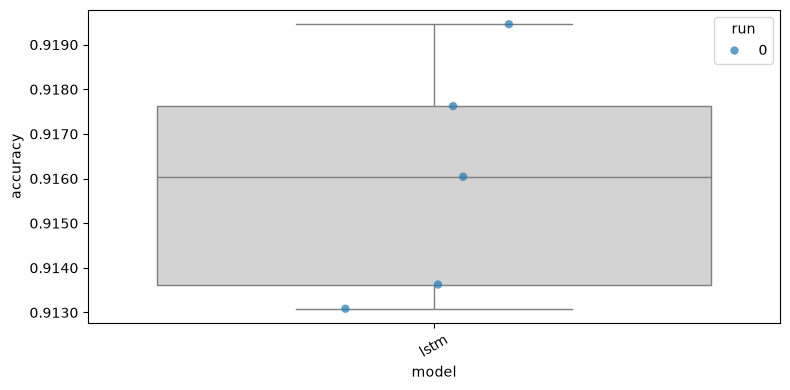

In [29]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

### Questions

1. Do you think the fact that the embeddings were pretrained actually made a difference for performance? Articulate reasons for and/or against. 
2. After all, nothing stops us from representing words in a continuous space _without_ having the specific GloVe parameters that we downloaded. In other words, we can always randomly initialise a matrix with as many rows as words in our vocabulary and as many columns as we want for our representations, and then let our training algorithm update those parameters end-to-end. Do you expect this to work? Articulate reasons for and/or against.
3. Generally, when do you expect the _knowledge_ from pretraining to make a difference? If you want to collect experimental data to shape your thoughts, consider subsetting your training data. As you reduce the amount of available data, you might see that the recurrent model struggles (and this also depends on the kinds of word embeddings you use).

**Suggested exercise:** Study the points above empirically. Also note that if you are free from the vocabulary choice made by the designers of the pretrained model, you can use all words in your corpus (though this will make your trainable embedding matrix grow) or even a completely different tokenizer (for example, one that allows you to choose vocabulary size; remember tutorial 1?).

## Analysis


We often turn to recurrent encoders because we believe the task is complex and requires better linguistic understanding. Sometimes we suspect a certain aspect of an input (its complexity, use of rare words, etc) is predictive of errors, or the distinguishing factor to explain the failure or success of one or another design. 

There are various ways to go about analysing our systems, their errors, and the kinds of properties we think our inputs exhibit. We would like you to gain some practical experience with it. 

One tool that is to use a dataset for analysis (something like a devtest set) and analyse inputs (in some feature space) in relation to a model's ability to predict the label correctly. A basic tool for that is a regression model. 

Suppose you collect some features of the input which are suggestive of their difficulty: length, presence of rare words, syntactic complexity (if you have a definition for it), a style flag (eg, formal, informal), information about its provenance (eg, newswire, social media, blogs), etc. A logistic regressor from this feature space to a correctness flag can help you characterse the relevance of each of these dimensions in explaining your model's accuracy. This is not bullet proof, but it's a useful methodology. 

There are various techniques for logist regression that are useful here. You can count sklearn LogisticRegressor, for example. It is helpful however to characterise the relevance of a feature as a statistical trend, rather than a fixed weight. Some regressors will offer you the ability to do what in ML is often called _automatic relevance determination_. This is inspired by Bayesian statistics. Typically, the regressor has a Laplace prior (or similar) for the weights of the features, encouraging them to be 0, unless sufficient evidence to the contrary can be gathered from the data. Sklearn offers you something very close to that, with `LogisticRegression(solver='liblinear', penalty='l1')`.

In the rest of this tutorial we use a very shallow, very basic Bayesian model, not because it's the last word in this kind of analysis, but to give you an opportunity to work with a Bayesian model, and, if you like, to give you a chance to learn from the code we share. Learning to design a Bayesian model, implement in python, and to overcome computational challenges are skills that we cannot really develop in this course. So, you get to choose how much you want to dig in this direction. 

For the purpose of this tutorial (and project), you may use our code or some other code, or you can turn to sklearn and work with non-Bayesian models. These are all fine options. 

## Load and assess trained models

First, let's demo how to load trained models and assess their performances.

Here for an embed-and-pool model:

In [30]:
em00 = part2.experiment.load(f"results/embed-and-pool/seed-0/fold-0/model", trained_emb_model)

In [35]:
em00_dt_logprobs = part2.experiment.predict_logprobs(em00, tokenizer_for_bow, [text for text, label in my_test_sets[0]['devtest']], 64, 'cpu')
em00_dt_logprobs.shape

(400, 4)

In [38]:
import numpy as np

In [36]:
from sklearn.metrics import classification_report

In [39]:
print(classification_report([label for text, label in my_test_sets[0]['devtest']], np.argmax(em00_dt_logprobs, -1), target_names=agnews_outcome_space.names))

              precision    recall  f1-score   support

       world       0.84      0.89      0.87        84
      sports       0.96      0.95      0.96       104
    business       0.86      0.85      0.86       109
 tech/sci-fi       0.86      0.83      0.85       103

    accuracy                           0.88       400
   macro avg       0.88      0.88      0.88       400
weighted avg       0.88      0.88      0.88       400



And here for a recurrent model:

In [40]:
rm00 = part2.experiment.load(f"results/lstm/seed-0/fold-0/model", trained_emb_model)
rm00_dt_logprobs = part2.experiment.predict_logprobs(em00, tokenizer_for_rnn, [text for text, label in my_test_sets[0]['devtest']], 64, 'cpu')
rm00_dt_logprobs.shape

(400, 4)

In [41]:
print(classification_report([label for text, label in my_test_sets[0]['devtest']], np.argmax(rm00_dt_logprobs, -1), target_names=agnews_outcome_space.names))

              precision    recall  f1-score   support

       world       0.86      0.86      0.86        84
      sports       0.96      0.94      0.95       104
    business       0.87      0.82      0.84       109
 tech/sci-fi       0.79      0.86      0.83       103

    accuracy                           0.87       400
   macro avg       0.87      0.87      0.87       400
weighted avg       0.87      0.87      0.87       400



Here we describe the devtest inputs in a basic feature space and assess correctness, we package it all in a pandas data frame, so it's easy to interoperate with sklearn and/or our BDA model.

In [42]:
# we will be using textstat as a way to otain some descriptive features of text; 
# we encourage you to look for things that are meaningful to your own task/dataset
# this is just to demo the kind of thing you can do 
import textstat  

import pandas as pd

table = []
systems = dict()
items = dict()

# each model uses a certain tokenizer, and we don't want to accidentally use the wrong one
name_to_tokenizer = {
    'embed-and-pool': tokenizer_for_bow, 
    'lstm': tokenizer_for_rnn
}

for model_family, model_data in my_classifiers.items(): # for all our trained classifiers
    for run, (seed, run_data) in enumerate(zip(my_seeds, model_data)):
        # we get the devtest set that we kep aside for each run
        # both texts and labels
        run_texts = [text for text, label in my_test_sets[run]['devtest']]
        run_labels = np.array([label for text, label in my_test_sets[run]['devtest']], dtype=int)
        
        for fold in range(num_folds):            
            # load our model
            trained_nn = part2.experiment.load(f"results/{model_family}/seed-{seed}/fold-{fold}/model", trained_emb_model)
            # test it on the devtest
            logprobs = part2.experiment.predict_logprobs(
                trained_nn, 
                name_to_tokenizer[model_family], 
                run_texts, 
                64, 
                'cpu'
            )
            preds = np.argmax(logprobs, -1)
    
            # then featurize the texts and compute the correctness flags
            for i in range(len(preds)):                
                                
                # find an int id for each system
                sid = systems.get(model_family, None)                
                if sid is None:
                    sid = len(systems)
                    systems[model_family] = sid
                # find an int id for each item
                item = my_test_sets[run]['devtest_ids'][i]                  
                item_id = items.get(item, None)                
                if item_id is None:
                    item_id = len(items)
                    items[item] = item_id

                # text, pred, and label
                x = run_texts[i]
                y_ = preds[i]
                y = run_labels[i]

                # put it all in a table, along with some features
                table.append([
                    model_family, 
                    item,
                    sid, 
                    item_id, 
                    run, 
                    fold, 
                    y, 
                    y_, 
                    int(y == y_), # correctness flag
                    # some features
                    textstat.lexicon_count(x),
                    textstat.flesch_reading_ease(x),
                    textstat.reading_time(x),
                    textstat.flesch_kincaid_grade(x)
                ])

df = pd.DataFrame(table, columns=['system', 'item', 'system_id', 'item_id', 'run', 'fold',  'label', 'pred', 'correct', 'lexicon_count', 'flesch_reading_ease', 'reading_time', 'flesch_kincaid_grade'])
df

,system,item,system_id,item_id,run,fold,label,pred,correct,lexicon_count,flesch_reading_ease,reading_time,flesch_kincaid_grade
0,lstm,3752,0,0,0,0,2,2,1,40,59.635000,2.73234,9.910000
1,lstm,4208,0,1,0,0,0,0,1,48,43.237500,3.80471,13.190833
2,lstm,2787,0,2,0,0,3,3,1,46,16.692826,3.55498,22.358696
3,lstm,4529,0,3,0,0,1,1,1,35,56.129643,2.57075,9.777857
4,lstm,3847,0,4,0,0,3,3,1,43,66.072587,3.09959,6.714128
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,lstm,4653,0,395,0,4,2,2,1,33,47.206705,3.17304,8.724470
1996,lstm,7069,0,396,0,4,1,1,1,28,48.493571,2.24757,13.451429
1997,lstm,3124,0,397,0,4,0,0,1,22,38.377727,1.77749,13.371818
1998,lstm,4555,0,398,0,4,3,3,1,29,31.537931,2.07129,16.064828


**BDA model.** The BDA model characterises the probability of correctness of an observation as a function of a global parameter (for the entire analysis), system-specific shifts (or biases), and system-specific linear combinations with input features. It allows us to appreciate the distribution of feature weights per system, as well as the distribution of each system's accuracy. This model takes as many systems as we want (it is not limited to 2). 

Observables:
* $c_n$ is the correctness label (0 or 1) for the $n$th observation 
* $s_n$ is the id of the system that produced the $n$th observation
* $\mathbf f_n$ is the vector of features that describe the $n$th input

Latent parameters (all priors are Laplace(0, 1), thus encouraging 0 weights):
* $\phi$: a global mean for the logit of the average correctness (in the entire analysis)
* $\boldsymbol{\delta}$: a vector of sytem biases (these are system-specific shifts in the global mean)
* $\mathbf {w}$: the feature weights, for each system (ie, with shape `num_systems x num_features`)

Likelihood function:
$$c_n | s_n, f_n \sim \operatorname{Bernoulli}(\operatorname{sigmoid}(\mu_n))$$
where the logit $\mu_n$ is defined as 
$$\mu_n = \phi + \delta_{s_n} + {\mathbf w}_{s_n}^\top f_n$$        

Below, we show how to "fit" the model via MCMC. For features we use the concatenation of a 4-dimensional one-hot encoding of the predicted label (not the observed label, the predicted one) and a 4-dimensional vector of continuous features from textstat. The implementation should be fine with many more features, but, if you have soooo many features that this is prohibitively slow, we recommend you to turn to sklearn LogisticRegression instead (as efficient BDA requires more time and more technical knowledge than we can cover in this course).

In [43]:
# Run with your inputs.
mcmc = part2.analysis.fit_bda_model(
    num_systems=len(systems), 
    sys_id=df['system_id'].to_numpy(), 
    # for features we have the one-hot encoding of the prediction (so we can learn if a system is better/worse at specific classes
    # as well as a few features that capture interesting aspects of the input text
    features=np.hstack(
        [
            part2.analysis.one_hot(df['pred'].to_numpy(), len(agnews_outcome_space)),  # K-dimensional pred indicator
            df[['lexicon_count', 'flesch_reading_ease', 'reading_time', 'flesch_kincaid_grade']].to_numpy() # 4 other features
        ]
    ),
    correctness=df['correct'].to_numpy(),
    num_chains=2
)
mcmc.print_summary()

sample: 100%|██████████| 2000/2000 [00:06<00:00, 331.56it/s, 127 steps of size 5.36e-02. acc. prob=0.93]



                   mean       std    median      5.0%     95.0%     n_eff     r_hat
  global_mean      1.87      1.19      2.04     -0.21      3.64    654.99      1.00
 sys_shift[0]      0.74      1.19      0.55     -1.17      2.66    658.44      1.00
       w[0,0]     -0.13      0.40     -0.11     -0.78      0.50    535.67      1.00
       w[0,1]      0.54      0.44      0.56     -0.16      1.22    577.73      1.00
       w[0,2]     -0.09      0.43     -0.07     -0.81      0.59    557.26      1.00
       w[0,3]     -0.16      0.42     -0.14     -0.85      0.50    523.04      1.00
       w[0,4]     -0.14      0.24     -0.13     -0.54      0.25    701.60      1.00
       w[0,5]     -0.20      0.24     -0.19     -0.62      0.15    690.60      1.00
       w[0,6]      0.32      0.27      0.30     -0.15      0.72    723.36      1.00
       w[0,7]     -0.16      0.20     -0.15     -0.50      0.15    751.50      1.00

Number of divergences: 0


First, a quick word on convergence. 

Posterior inference is often intractable to be done exactly. Instead, we resort to techniques such as MCMC. 

MCMC is a form of approximate inference (it samples _approximately_ from the model's true posterior distribution). So most MCMC algorithms ship some "convergence diagnostics"; these measure properties of multiple simulated chains looking for evidence of problems. This model is simple enough that MCMC should do really well here, and we don't expect problems. But here's what we expect to read from the summary that the code above produced:

* Ideally, the summary above shows r_hat values that are all 1.0 or very close to 1.0 (otherwise, MCMC struggled to converge).
* Also, the report below would sould 0 (or very few) divergences.


In [44]:
posterior = mcmc.get_samples()
print("Weight samples:", posterior["w"].shape)
print("System shift samples:", posterior["sys_shift"].shape)
print("Divergences:", int(mcmc.get_extra_fields()["diverging"].sum()))

Weight samples: (2000, 1, 8)
System shift samples: (2000, 1)
Divergences: 0


It is relatively easy to get interesting plots using arviz. We have some helper code to package the MCMC output as the kind of data frame arviz likes:

In [13]:
posterior_data = part2.analysis.posterior_to_arviz(
    mcmc,
    # you need only name the systems
    system_names=[name for name, _ in sorted(systems.items(), key=lambda pair: pair[1])],
    # and the features
    feature_names=[f"pred:{n}" for n in agnews_outcome_space.names] + ['lexicon_count', 'flesch_reading_ease', 'reading_time', 'flesch_kincaid_grade']
) 

NameError: name 'mcmc' is not defined

Then we can view the posterior distribution over system shift parameters: these are scalars that capture a system's tendency to push the probability of correctness higher or lower. It's not necessary super easy to interpret this number, because this parameters affects a logit (that is, the correctness probability is obtained after combining other quantities and applying sigmoid), but higher positive values indicate better systems.

In [46]:
az_stats_params = {'point_estimate': 'median', 'ci_kind': 'hdi', 'ci_probs': (0.5, 0.95)}

In [48]:
import arviz as az

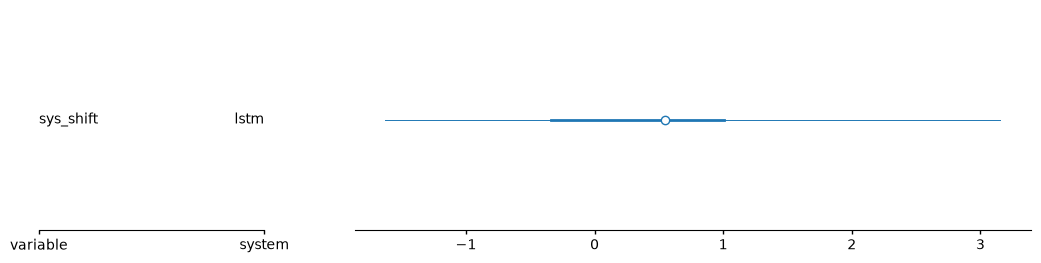

In [49]:
az.plot_forest(
    posterior_data, 
    var_names=['sys_shift'],    
    combined=True,           # Combine chains
    **az_stats_params
)

It's easier to appreciate posterior accuracy. This will not differ much from what you saw with `plot_box_and_points`:

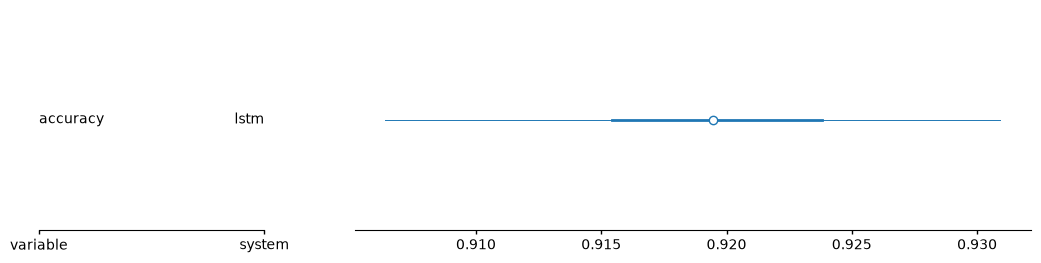

In [50]:
az.plot_forest(
    posterior_data, 
    var_names=['accuracy'],    
    combined=True,           # Combine chains
    **az_stats_params
)

And the most interesting thing this model offers, like any other linear model, is a view of the importance of the different features:

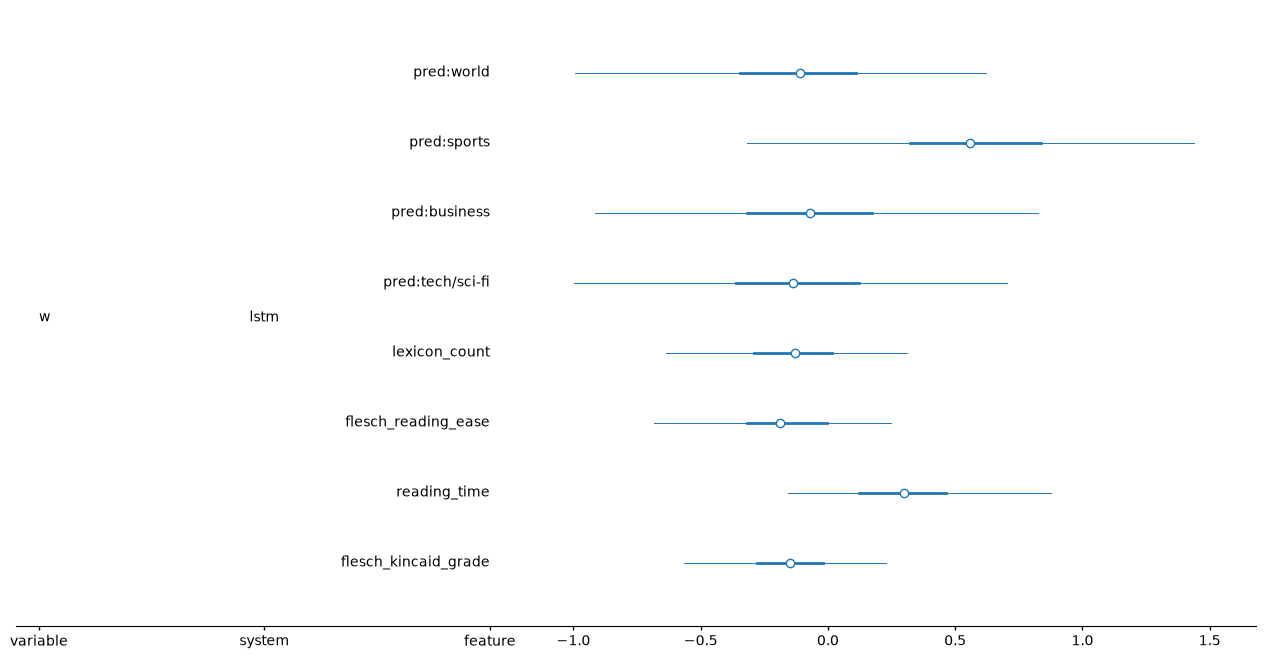

In [51]:
az.plot_forest(
    posterior_data, 
    var_names=['w'],    
    combined=True,           # Combine chains    
    shade_label="system",
    figure_kwargs={
        "figsize": (16, 8),
        "width_ratios": [2, 3],  # Label panel : interval panel
        "layout": "none",
    },
    **az_stats_params,
)

You might find it easier to group the plots differently, putting systems side by side for each feature:

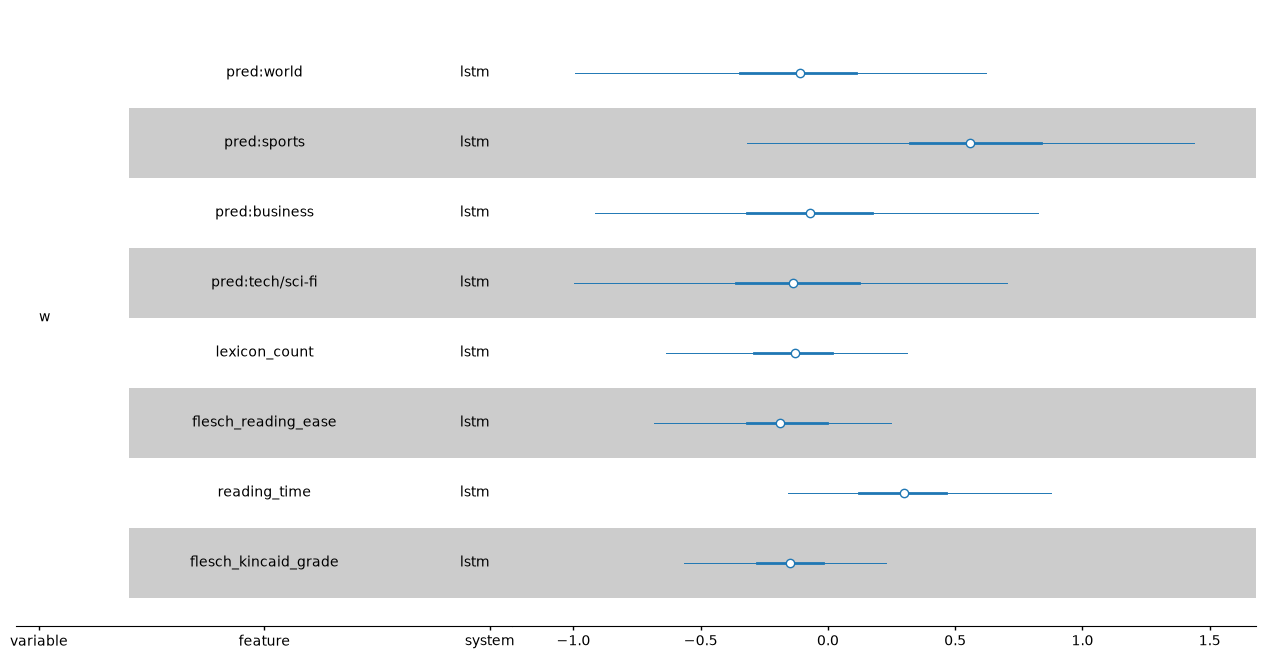

In [52]:
# Create a plotting copy containing only w, with reordered dimensions.
plot_data = posterior_data.copy()
plot_data["posterior"] = (
    posterior_data.posterior["w"]
    .transpose("chain", "draw", "feature", "system")
    .to_dataset()
)

az.plot_forest(
    plot_data,
    var_names=["w"],
    combined=True,
    shade_label="feature",
    figure_kwargs={
        "figsize": (16, 8),
        "width_ratios": [2, 3],
        "layout": "none",
    },
    **az_stats_params,
)

Usually, by inspecting these, you can learn something about what kinds of inputs (in terms of what kinds of features they have) models' performances differ most as a function of. As we have standardised the features (`fit_bda_model` sees to it) we can interpret feature weights:
* A contribution close to 0 is telling the feature is not particularly useful in describing the model's correctness distribution.
* A contribution larger than 0 suggests that your model is doing well along instances where that feature fires (or where that feature is largest);
* conversely, a contribution less than 0 suggests that your model is struggling as that feature fires (or grows larger).

### Questions

1. Coming up with a list of features to test is not necessarily obvious, and it's not really the job of statistical analysis. That is to job of the scientist. You need to formulate plausible ideas. Error analysis with more or less systematicity, intuition, and prior knowledge (from literature in the field) are the main tools. Once you have some thoughts, you can turn to statistical analysis to look for empirical support. Start with this. What features would like to test? Discus some, discuss why, and find ways to code them up. It's okay to rely on external resources.
2. Now try to analyse performance differences in terms of these features. See you the empirical data supports your intuitions. Sometimes you will want to iterate (1) and (2). Did you find anything worth discussing? Does it open up paths for future investigations?